# U01d — Unique likelihood-guard ablation

Goal: isolate the effect of the **word-path relative-likelihood guard** while keeping the established **Unique** controller active.

Frozen design:

- generator: `meta-llama/Llama-3.2-3B-Instruct`
- 20 frozen U01 prompts
- context: **WITH_PREV**
- temporal method: **FULL** only
- Unique intervention: same controller, human prefix curves, stronger-downward policy, search budget, and token cap as U01b
- guard arms generated here:
  - `GUARD_001`: relative word-path likelihood floor = `0.01`
  - `NO_GUARD`: no relative-likelihood rejection
- existing U01b `FULL` output is the `0.05` arm and is **not regenerated**
- `MAX_NEW_TOKENS = 640`
- total new generations: **20 × 2 = 40**

The notebook checkpoints after every generation and preserves the full controller state for audit.

This notebook reuses the canonical Unique definitions from `C02w2_regenerate_top5.ipynb` and only the `JointTemporalBackend` class from U01b. Because this experiment is FULL-only, the temporal-history multiplier is defined directly as the exact FULL contract `lambda=1.0`, avoiding execution-order dependencies from U01b analysis cells.

**v3 fix:** explicitly loads U01b's `lambda_full`/schedule-helper cell before constructing `JointTemporalBackend`.


In [1]:
from pathlib import Path
import ast, copy, gc, hashlib, json, math
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

ROOT = Path.cwd().resolve()
if ROOT.name == "experiments":
    ROOT = ROOT.parent
if not (ROOT / "results").exists() and (ROOT.parent / "results").exists():
    ROOT = ROOT.parent

assert (ROOT / "experiments").exists(), ROOT

U01B_NB = ROOT / "experiments/U01b_joint_unique_temporal_withprev.ipynb"
UNIQUE_NB = ROOT / "experiments/C02w2_regenerate_top5.ipynb"

assert U01B_NB.exists(), U01B_NB
assert UNIQUE_NB.exists(), UNIQUE_NB

OUT = ROOT / "results/causal/U01d_unique_guard_ablation"
OUT.mkdir(parents=True, exist_ok=True)

STATE_DIR = OUT / "states"
STATE_DIR.mkdir(exist_ok=True)

GEN_PATH = OUT / "guard_ablation_generations.parquet"

MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"
MAX_NEW_TOKENS = 640
DOWNWARD_THETA_MULTIPLIER = 0.25

GUARD_ARMS = {
    "GUARD_001": 0.01,
    "NO_GUARD": None,
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float16 if device.type == "cuda" else torch.float32

print("ROOT:", ROOT)
print("Output:", OUT)
print("Device:", device)
print("Guard arms:", GUARD_ARMS)

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
Output: ../results/causal/U01d_unique_guard_ablation
Device: cuda
Guard arms: {'GUARD_001': 0.01, 'NO_GUARD': None}


## Load frozen U01 cohort + case contracts

In [2]:
# Reconstruct the exact cohort and Unique contracts used by U01b.
# Do this directly rather than executing a U01b setup cell, so this notebook
# is self-contained with respect to setup order.

PAIR_PATH = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet"
U01_OUT = ROOT / "results/causal/U01_temporal_method_selection"
COHORT_PATH = U01_OUT / "cohort20.csv"
UNIQUE_PARENT = ROOT / "results/causal/C02r_discovery_gated_punctuation"
CONTRACT_PATH = UNIQUE_PARENT / "frozen_contract.json"

for _p in [PAIR_PATH, COHORT_PATH, CONTRACT_PATH]:
    assert _p.exists(), _p

cohort = pd.read_csv(COHORT_PATH, keep_default_na=False)
assert len(cohort) == 20 and cohort.case_id.is_unique

paired = pd.read_parquet(PAIR_PATH).copy()

def raw_id(x):
    x = str(x)
    return x.split("ai__raid:", 1)[1] if x.startswith("ai__raid:") else x

paired["raw_id"] = paired.source_id.astype(str).map(raw_id)
exact = paired.drop_duplicates("source_id").set_index("source_id").text.to_dict()
rawmap = paired.drop_duplicates("raw_id").set_index("raw_id").text.to_dict()

cohort["raw_id"] = cohort.source_id.astype(str).map(raw_id)
cohort["previous_ai"] = cohort.source_id.astype(str).map(exact)
miss = cohort.previous_ai.isna()
cohort.loc[miss, "previous_ai"] = cohort.loc[miss, "raw_id"].map(rawmap)
assert cohort.previous_ai.notna().all()
assert "prompt" in cohort.columns, cohort.columns.tolist()

# Canonical Unique frozen contract used by U01b.
unique_contract = json.loads(CONTRACT_PATH.read_text())
UNIQUE_THETA_SCHEDULES = copy.deepcopy(unique_contract["theta_schedules"])
MAX_COMPLETED_CANDIDATES = int(unique_contract["max_completed_candidates"])

case_contract = {
    str(c["case_id"]): copy.deepcopy(c)
    for c in unique_contract["cases"]
}

missing_cases = sorted(set(cohort.case_id.astype(str)) - set(case_contract))
assert not missing_cases, f"U01d cases absent from Unique frozen contract: {missing_cases}"

# U01b notebook is still read later only to recover the exact backend class.
u01b_nb = json.loads(U01B_NB.read_text())
code_cells = [
    "".join(c.get("source", []))
    for c in u01b_nb["cells"]
    if c.get("cell_type") == "code"
]

print("Cases:", len(cohort))
print("Unique contract:", CONTRACT_PATH)
print("Theta schedules:", UNIQUE_THETA_SCHEDULES)
print("Max completed candidates:", MAX_COMPLETED_CANDIDATES)
display(cohort[["case_id", "source_id", "domain"]])


Cases: 20
Unique contract: ../results/causal/C02r_discovery_gated_punctuation/frozen_contract.json
Theta schedules: {'increase': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}, 'decrease': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}}
Max completed candidates: 500


,case_id,source_id,domain
0,gate_0090,ai__raid:e3945a96-7048-41d9-9e86-a84e87818986,abstracts
1,gate_0070,ai__raid:7a3b622e-1e88-48ce-98e0-2f87da5c573c,books
2,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news
3,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes
4,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit
5,gate_0039,ai__raid:8760103e-729a-4bab-b799-5775ac2468b1,wiki
6,gate_0069,ai__raid:c7b5fc38-2bbb-4e44-bba7-dc8ac8eae773,abstracts
7,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books
8,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news
9,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes


## Load canonical Unique controller

In [3]:
# Load the canonical Unique controller from C02w2 without executing generation cells.

src_nb = json.loads(UNIQUE_NB.read_text())

import heapq
import spacy
from collections import Counter

nlp = spacy.load("en_core_web_sm")
PILOT = {"downward_theta_multiplier": DOWNWARD_THETA_MULTIPLIER}

def _cell_source(marker):
    hits = [
        "".join(cell.get("source", []))
        for cell in src_nb["cells"]
        if cell.get("cell_type") == "code"
        and marker in "".join(cell.get("source", []))
    ]
    assert len(hits) == 1, (marker, len(hits))
    return hits[0]

def _assigned_names(node):
    names = []
    if isinstance(node, ast.Assign):
        targets = node.targets
    elif isinstance(node, ast.AnnAssign):
        targets = [node.target]
    else:
        return names
    for target in targets:
        if isinstance(target, ast.Name):
            names.append(target.id)
    return names

def _exec_selected(src, predicate):
    tree = ast.parse(src)
    body = [node for node in tree.body if predicate(node)]
    exec(compile(ast.Module(body=body, type_ignores=[]), str(UNIQUE_NB), "exec"), globals())

helper_src = _cell_source("# Human prefix references and adaptive control helpers.")
_exec_selected(helper_src, lambda node: isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)))

engine_src = _cell_source("# Word feedback engine. Pure Python")
_exec_selected(
    engine_src,
    lambda node: isinstance(node, (ast.Import, ast.ImportFrom, ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)),
)

budget_src = _cell_source("class WordSearchBudgetReached")
_budget_assigns = {"SEARCH_BUDGET", "_search_word_before_budget", "budgeted_search", "RUNAWAY_POLICY"}
_budget_funcs = {"search_word", "repeated_suffix", "runaway_reason", "show_repetition_onset"}
_budget_classes = {"WordSearchBudgetReached", "RunawayGeneration"}

def _keep_budget_node(node):
    if isinstance(node, (ast.Assign, ast.AnnAssign)):
        return any(name in _budget_assigns for name in _assigned_names(node))
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        return node.name in _budget_funcs
    if isinstance(node, ast.ClassDef):
        return node.name in _budget_classes
    return False

_exec_selected(budget_src, _keep_budget_node)

guard_src = _cell_source("def word_path_logp")
_exec_selected(
    guard_src,
    lambda node: isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)) and node.name in {"word_path_logp", "make_search"},
)

# U01b/C02w2 stronger-downward policy.
_u01d_base_adaptive_mode = adaptive_mode
_u01d_base_adaptive_theta = adaptive_theta

def adaptive_mode(previous, V, W, warmup_words, ref):
    mode = _u01d_base_adaptive_mode(previous, V, W, warmup_words, ref)
    if W >= warmup_words and W > 0 and ref.get("supported", False) and V / W > ref["H_median"]:
        return "decrease"
    return mode

def adaptive_theta(mode, k, w, ref, schedules):
    theta, q = _u01d_base_adaptive_theta(mode, k, w, ref, schedules)
    if theta is not None and mode == "decrease":
        theta *= DOWNWARD_THETA_MULTIPLIER
    return theta, q

required = {
    "reference_at", "adaptive_mode", "adaptive_theta", "word_spans", "counts",
    "first_closed_word", "greedy_to_word", "backtrack_anchor", "search_word",
    "initial_state", "run_feedback", "WordSearchBudgetReached",
    "_search_word_before_budget", "budgeted_search", "word_path_logp", "make_search",
}
missing = required - set(globals())
assert not missing, f"Unique engine extraction missing: {sorted(missing)}"

print("Canonical Unique engine loaded.")
print("Search budget:", SEARCH_BUDGET)

Canonical Unique engine loaded.
Search budget: {'version': 'word_search_budget_pilot_v1', 'max_expanded': 1000, 'max_frontier': 10000}


## Load Llama and build WITH_PREV prompt

In [4]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

tok = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=dtype,
    low_cpu_mem_usage=True,
).to(device).eval()

eos = model.generation_config.eos_token_id
if eos is None:
    eos = tok.eos_token_id
EOS_IDS = set(eos if isinstance(eos, (list, tuple)) else [eos])
FORBIDDEN_SPECIAL = set(tok.all_special_ids) - EOS_IDS

class TokenCapReached(RuntimeError):
    pass

def build_messages(prompt, previous_ai):
    content = (
        f"Original task:\n{prompt}\n\n"
        f"Previous AI answer:\n{previous_ai}\n\n"
        "Generate a fresh complete answer to the original task. "
        "Preserve the substantive content of the previous AI answer."
    )
    return [{"role": "user", "content": content}]

def prompt_ids(prompt, previous_ai):
    rendered = tok.apply_chat_template(
        build_messages(prompt, previous_ai),
        tokenize=False,
        add_generation_prompt=True,
    )
    return tok(
        rendered,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"][0].tolist()

print("Loaded:", MODEL_ID)
print("EOS:", EOS_IDS)
if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    print(f"CUDA free after load: {free/2**30:.2f}/{total/2**30:.2f} GiB")


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 254/254 [00:00<00:00, 438.31it/s]


Loaded: meta-llama/Llama-3.2-3B-Instruct
EOS: {128008, 128001, 128009}
CUDA free after load: 0.44/7.62 GiB


## FULL-only temporal schedule contract

In [5]:
# U01d only runs the U01b FULL arm. For FULL, U01b's temporal-history
# multiplier is identically 1.0 at every generated-token position.
#
# Define that contract directly instead of executing U01b's larger schedule/plot
# cell (which also depends on notebook-only globals such as METHODS).

def lambda_full(method, t):
    if method != "FULL":
        raise ValueError(f"U01d is FULL-only; unexpected temporal method: {method!r}")
    return 1.0

assert lambda_full("FULL", 0) == 1.0
assert lambda_full("FULL", 639) == 1.0
print("FULL temporal-history multiplier fixed at 1.0 for all positions.")


FULL temporal-history multiplier fixed at 1.0 for all positions.


## Load the U01b backend class + dependency smoke test

In [6]:
# U01d patch — dependency used by JointTemporalBackend._distribution()
import torch.nn.functional as F

print("Loaded torch.nn.functional as F")

Loaded torch.nn.functional as F


In [7]:
# Recover ONLY the JointTemporalBackend class definition from U01b.
# Do not execute any other top-level code from that notebook cell.
#
# NOTE: inspect.getclosurevars(...).unbound is NOT appropriate here because
# Python records attribute names (e.g. .clone, .decode, .append) in co_names,
# which makes ordinary method attributes look like unresolved globals.
# We instead inspect only actual LOAD_GLOBAL / LOAD_NAME bytecode operations.

import builtins
import dis

backend_hits = [
    s for s in code_cells
    if "class JointTemporalBackend:" in s
    and "def _distribution(self,ids):" in s
]
assert len(backend_hits) == 1, f"Expected one backend cell, found {len(backend_hits)}"

_backend_tree = ast.parse(backend_hits[0])
_backend_classes = [
    node for node in _backend_tree.body
    if isinstance(node, ast.ClassDef) and node.name == "JointTemporalBackend"
]
assert len(_backend_classes) == 1

exec(
    compile(
        ast.Module(body=_backend_classes, type_ignores=[]),
        str(U01B_NB),
        "exec",
    ),
    globals(),
)

assert MAX_NEW_TOKENS == 640
assert lambda_full("FULL", 128) == 1.0


def _missing_true_globals(fn):
    """Return names actually loaded as globals that are not available."""
    missing = set()

    for ins in dis.get_instructions(fn):
        if ins.opname not in {"LOAD_GLOBAL", "LOAD_NAME"}:
            continue

        name = ins.argval

        if name in fn.__globals__:
            continue

        if hasattr(builtins, name):
            continue

        missing.add(name)

    return sorted(missing)


# Audit the exact functions used by the generation path.
_guarded_001 = make_search(0.01)
_guarded_none = make_search(None)

_check_functions = {
    "JointTemporalBackend._distribution": JointTemporalBackend._distribution,
    "JointTemporalBackend.choices": JointTemporalBackend.choices,
    "JointTemporalBackend.decode": JointTemporalBackend.decode,
    "run_feedback": run_feedback,
    "search_word": search_word,
    "budgeted_search": budgeted_search,
    "word_path_logp": word_path_logp,
    "make_search": make_search,
    "make_search(0.01)": _guarded_001,
    "make_search(None)": _guarded_none,
}

_missing_globals = {}

for _name, _fn in _check_functions.items():
    _missing = _missing_true_globals(_fn)
    if _missing:
        _missing_globals[_name] = _missing

assert not _missing_globals, (
    f"True unresolved globals before generation: {_missing_globals}"
)

del _guarded_001, _guarded_none


# One REAL FULL-history forward pass.
# This catches backend/runtime dependencies that static inspection can miss,
# without writing experiment output.
_test_src = cohort.iloc[0]

_test_backend = JointTemporalBackend(
    prompt_ids(
        _test_src.prompt,
        _test_src.previous_ai,
    ),
    "FULL",
)

_test_choices = _test_backend.choices(
    [],
    threshold=None,
)

assert len(_test_choices) > 0
assert _test_backend.forward_calls == 1

del _test_backend, _test_choices, _test_src

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(
    "Backend/controller preflight passed: "
    "true-global audit + one real FULL forward pass."
)

Backend/controller preflight passed: true-global audit + one real FULL forward pass.


## Generate the 0.01 and no-guard arms

In [8]:
# Final guard-specific preflight.
assert callable(make_search(0.01))
assert callable(make_search(None))

# Preflight before any expensive generation.
_required = [
    "make_search", "run_feedback", "initial_state", "reference_at",
    "counts", "JointTemporalBackend", "UNIQUE_THETA_SCHEDULES",
]
_missing = [name for name in _required if name not in globals()]
assert not _missing, f"U01d preflight missing globals: {_missing}"
assert len(cohort) == 20
assert set(GUARD_ARMS) == {"GUARD_001", "NO_GUARD"}

if GEN_PATH.exists():
    guard_gen = pd.read_parquet(GEN_PATH)
    if "controller_status" in guard_gen.columns:
        failed = guard_gen["controller_status"].astype(str).eq("failed_exception")
        if failed.any():
            print("Dropping failed checkpoint rows:", int(failed.sum()))
            guard_gen = guard_gen.loc[~failed].reset_index(drop=True)
            guard_gen.to_parquet(GEN_PATH, index=False)
else:
    guard_gen = pd.DataFrame()

if len(guard_gen):
    done = set(zip(guard_gen["case_id"].astype(str), guard_gen["guard_arm"].astype(str)))
else:
    done = set()

total = len(cohort) * len(GUARD_ARMS)
pbar = tqdm(total=total, initial=len(done), desc="U01d Unique guard ablation")

for src in cohort.itertuples(index=False):
    cid = str(src.case_id)
    c = case_contract[cid]
    curve = c["curve"]
    warmup_words = int(c["warmup_words"])
    pids = prompt_ids(src.prompt, src.previous_ai)

    for guard_arm, guard_ratio in GUARD_ARMS.items():
        if (cid, guard_arm) in done:
            continue

        backend = JointTemporalBackend(pids, "FULL")
        state = initial_state(f"WITH_PREV_UNIQUE_FULL_{guard_arm}")

        # make_search(None) keeps Unique search active while bypassing only
        # the relative-likelihood rejection stage.
        globals()["search_word"] = make_search(guard_ratio)

        try:
            run_feedback(backend, state, curve, warmup_words, UNIQUE_THETA_SCHEDULES)
        except TokenCapReached:
            state["finished"] = False
            state["status"] = "truncated_token_cap"
        except Exception as e:
            state["finished"] = False
            state["status"] = "failed_exception"
            state["exception"] = repr(e)

        text = backend.decode(state.get("ids", []))
        V, W = counts(text)
        k = V / W if W else np.nan
        ref = reference_at(curve, W) if W else {"supported": False}
        in_band = bool(ref.get("supported", False)) and np.isfinite(k) and ref["H_h30"] <= k <= ref["H_a10"]

        traj = state.get("trajectory", [])
        replacements = sum(t.get("action", "ordinary") != "ordinary" for t in traj)
        fallbacks = sum(bool(t.get("fallback_reason")) for t in traj)
        searches = sum(int(t.get("search_expanded", 0) > 0) for t in traj)

        if state["status"] == "completed_eos":
            stop_reason = "eos"
        elif state["status"] == "truncated_token_cap":
            stop_reason = "truncated"
        elif "runaway" in str(state["status"]):
            stop_reason = "runaway_guard"
        elif state["status"] == "failed_exception":
            stop_reason = "exception"
        else:
            stop_reason = str(state["status"])

        row = {
            "case_id": cid,
            "source_id": src.source_id,
            "domain": src.domain,
            "temporal_method": "FULL",
            "guard_arm": guard_arm,
            "guard_ratio": np.nan if guard_ratio is None else float(guard_ratio),
            "guard_enabled": guard_ratio is not None,
            "unique_control": True,
            "with_prev": True,
            "model_id": MODEL_ID,
            "generated_text": text,
            "generator_tokens": len(state.get("ids", [])),
            "stop_reason": stop_reason,
            "controller_status": state["status"],
            "word_count": W,
            "unique_words": V,
            "share_unique_words": k,
            "reference_supported": bool(ref.get("supported", False)),
            "H_h30": ref.get("H_h30", np.nan),
            "H_h10": ref.get("H_h10", np.nan),
            "H_median": ref.get("H_median", np.nan),
            "H_a10": ref.get("H_a10", np.nan),
            "unique_in_band": bool(in_band),
            "unique_replacements": replacements,
            "unique_fallbacks": fallbacks,
            "unique_search_words": searches,
            "backend_forward_calls": backend.forward_calls,
            "text_sha": hashlib.sha256(text.encode()).hexdigest(),
        }

        audit = {
            "case_id": cid,
            "guard_arm": guard_arm,
            "guard_ratio": guard_ratio,
            "temporal_method": "FULL",
            "state": state,
            "summary": row,
        }
        (STATE_DIR / f"{cid}__{guard_arm}.json").write_text(
            json.dumps(audit, ensure_ascii=False, indent=2, default=float)
        )

        guard_gen = pd.concat([guard_gen, pd.DataFrame([row])], ignore_index=True) if len(guard_gen) else pd.DataFrame([row])
        guard_gen.to_parquet(GEN_PATH, index=False)

        done.add((cid, guard_arm))
        pbar.update(1)

        if state["status"] == "failed_exception":
            pbar.close()
            raise RuntimeError(f"{cid}/{guard_arm} failed: {state.get('exception')}")

pbar.close()

assert len(guard_gen) == 40, (len(guard_gen), 40)
assert guard_gen[["case_id", "guard_arm"]].drop_duplicates().shape[0] == 40

print("Saved:", GEN_PATH)
print("Completed:", len(guard_gen), "/ 40")

display(
    guard_gen.groupby("guard_arm").agg(
        n=("case_id", "size"),
        eos=("stop_reason", lambda x: int((x == "eos").sum())),
        truncated=("stop_reason", lambda x: int((x == "truncated").sum())),
        mean_tokens=("generator_tokens", "mean"),
        mean_unique=("share_unique_words", "mean"),
        unique_in_band_rate=("unique_in_band", "mean"),
        mean_replacements=("unique_replacements", "mean"),
        mean_fallbacks=("unique_fallbacks", "mean"),
    )
)

Dropping failed checkpoint rows: 1


U01d Unique guard ablation: 100%|████████████████████████████████████████████████████████████████████| 40/40 [2:07:06<00:00, 190.65s/it]

Saved: ../results/causal/U01d_unique_guard_ablation/guard_ablation_generations.parquet
Completed: 40 / 40


,n,eos,truncated,mean_tokens,mean_unique,unique_in_band_rate,mean_replacements,mean_fallbacks
guard_arm,,,,,,,,
GUARD_001,20,18,2,394.8,0.525234,0.2,71.65,59.3
NO_GUARD,20,18,2,392.7,0.529944,0.2,67.00,55.3


## Combine with existing 0.05 FULL arm

In [9]:
U01B_OUT = ROOT / "results/causal/U01b_joint_unique_temporal_withprev"
U01B_GEN = U01B_OUT / "joint_generations.parquet"
assert U01B_GEN.exists(), U01B_GEN

u01b_gen = pd.read_parquet(U01B_GEN)
guard005 = u01b_gen.loc[
    u01b_gen["method"].eq("FULL")
    & ~u01b_gen["controller_status"].astype(str).eq("failed_exception")
].copy()

assert len(guard005) == 20 and guard005["case_id"].is_unique

guard005 = guard005.assign(
    guard_arm="GUARD_005",
    guard_ratio=0.05,
    guard_enabled=True,
    temporal_method="FULL",
)

common = sorted(set(guard005.columns) & set(guard_gen.columns))
three_arm = pd.concat([guard005[common], guard_gen[common]], ignore_index=True)
assert three_arm[["case_id", "guard_arm"]].drop_duplicates().shape[0] == 60

THREE_ARM_PATH = OUT / "guard_ablation_all_three_arms.parquet"
three_arm.to_parquet(THREE_ARM_PATH, index=False)

print("Saved three-arm panel:", THREE_ARM_PATH)
display(
    three_arm.groupby("guard_arm").agg(
        n=("case_id", "size"),
        mean_tokens=("generator_tokens", "mean"),
        mean_unique=("share_unique_words", "mean"),
        unique_in_band_rate=("unique_in_band", "mean"),
        mean_replacements=("unique_replacements", "mean"),
        mean_fallbacks=("unique_fallbacks", "mean"),
    )
)

Saved three-arm panel: ../results/causal/U01d_unique_guard_ablation/guard_ablation_all_three_arms.parquet


,n,mean_tokens,mean_unique,unique_in_band_rate,mean_replacements,mean_fallbacks
guard_arm,,,,,,
GUARD_001,20,394.8,0.525234,0.20,71.65,59.30
GUARD_005,20,391.0,0.545918,0.15,76.25,70.15
NO_GUARD,20,392.7,0.529944,0.20,67.00,55.30


In [11]:
# U01d -> U01c scorer handoff
# Generation is complete, so release Llama and load the frozen Qwen scorer.

import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# Free generator VRAM.
for name in ["model", "tok"]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SCORER_ID = "Qwen/Qwen3-0.6B-Base"
scorer_dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)

stok = AutoTokenizer.from_pretrained(
    SCORER_ID,
    use_fast=True,
)

smodel = AutoModelForCausalLM.from_pretrained(
    SCORER_ID,
    dtype=scorer_dtype,
    low_cpu_mem_usage=True,
).to(device).eval()

print("Loaded scorer:", SCORER_ID)

if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    print(
        f"CUDA free: {free / 2**30:.2f} / "
        f"{total / 2**30:.2f} GiB"
    )

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 2884.81it/s]


Loaded scorer: Qwen/Qwen3-0.6B-Base
CUDA free: 5.42 / 7.62 GiB


Cases: 20


,case_id,domain
0,gate_0090,abstracts
1,gate_0070,books
2,gate_0017,news
3,gate_0085,recipes
4,gate_0038,reddit
5,gate_0039,wiki
6,gate_0069,abstracts
7,gate_0035,books
8,gate_0003,news
9,gate_0025,recipes


Scoring guard ablation: 100%|███████████████████████████████████████████████████████████████████████████| 80/80 [00:16<00:00,  4.82it/s]

Cases surviving post-20% cut: 20 / 20


,case_id,OG_total_tokens,cut_token_20pct,matched_end_token,post_cut_positions
0,gate_0090,229,46,206,160
1,gate_0070,267,54,255,201
2,gate_0017,394,79,255,176
3,gate_0085,299,60,255,195
4,gate_0038,142,29,141,112
5,gate_0039,207,42,206,164
6,gate_0069,129,26,128,102
7,gate_0035,265,53,255,202
8,gate_0003,427,86,255,169
9,gate_0025,341,69,255,186



Post-20% surprisal summary:


,n,mean,median,q75,q90,q95,q99
condition,,,,,,,
OG,3400,1.799237,0.972814,2.606926,4.847604,6.408674,9.670381
GUARD_005,3400,1.660882,0.939354,2.447556,4.410323,5.841796,9.043562
GUARD_001,3400,1.586677,0.853122,2.319350,4.310344,5.671769,8.567214
NO_GUARD,3400,1.611528,0.890238,2.334922,4.341691,5.777686,8.756140



Post-20% tail frequencies:


P_S_gt_tau                               E_S_given_tail             \
condition  GUARD_001 GUARD_005  NO_GUARD        OG      GUARD_001  GUARD_005   
tau                                                                            
4           0.115588  0.123235  0.117941  0.142941       5.896898   5.920628   
6           0.041765  0.045000  0.043235  0.060882       7.734454   7.775169   
8           0.012059  0.013824  0.013529  0.023529      10.106493  10.094071   
10          0.004706  0.005294  0.004706  0.009118      11.897832  11.740437   

                                 
condition   NO_GUARD         OG  
tau                              
4           5.900257   6.257867  
6           7.734929   8.125570  
8           9.983989  10.175108  
10         11.894819  12.197441

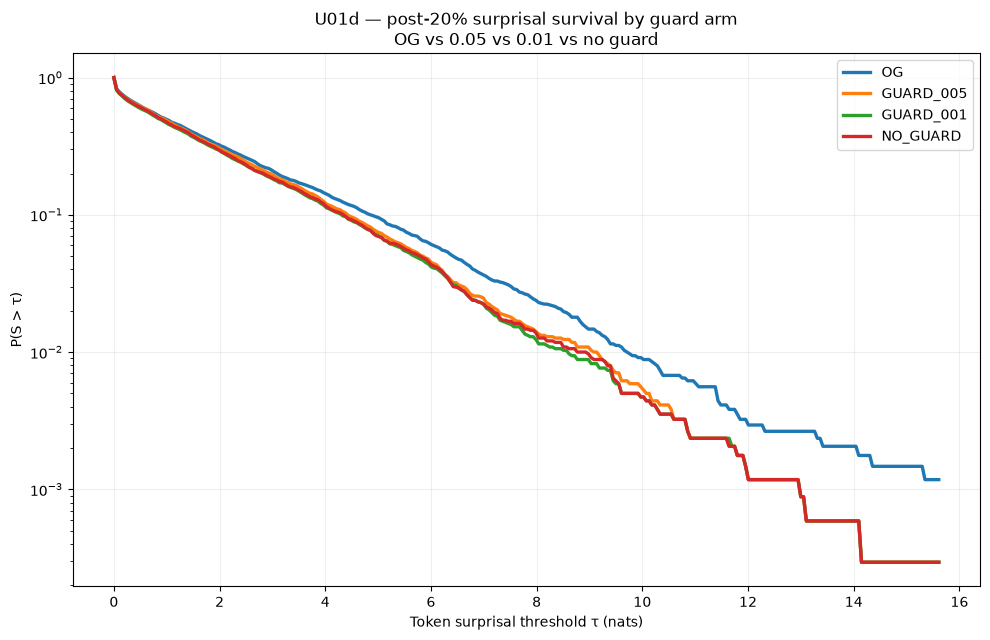

Saved plot to: ../results/causal/U01d_unique_guard_ablation/guard_ablation_post20pct_surprisal_survival.png


In [12]:
# U01d / U01c bridge — surprisal survival graph for
# OG vs GUARD_005 vs GUARD_001 vs NO_GUARD
#
# Assumes:
#   - `three_arm` already exists
#   - the U01c scorer is already loaded as `stok`, `smodel`, and `device`
#     (if not, load the same scorer you used in U01c first)
#
# Design:
#   - score each OG text and each of the 3 guard-arm outputs
#   - truncate each condition to a common matched prefix per case
#   - discard the first 20% of OG scorer tokens (warmup cut)
#   - graph the survival curve P(S > τ)

from pathlib import Path
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from IPython.display import display

assert "three_arm" in globals(), "Run the three-arm combine cell first."
assert "stok" in globals() and "smodel" in globals() and "device" in globals(), \
    "Load the same U01c scorer first (stok / smodel / device)."
assert "ROOT" in globals() and "OUT" in globals() and "cohort" in globals()

PAIR_PATH = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet"
assert PAIR_PATH.exists(), PAIR_PATH

MAX_COMPARE_TOKENS = 256
POST_CUT_FRACTION = 0.20
SCORE_CACHE = OUT / "guard_ablation_positional_surprisal.parquet"

ARMS = ["GUARD_005", "GUARD_001", "NO_GUARD"]
CONDITIONS = ["OG"] + ARMS


# ------------------------------------------------------------
# 1) Recover the exact OG texts used by the 20-case cohort.
# ------------------------------------------------------------

paired = pd.read_parquet(PAIR_PATH).copy()

def _raw_id(x):
    x = str(x)
    return x.split("ai__raid:", 1)[1] if x.startswith("ai__raid:") else x

paired["raw_id"] = paired["source_id"].astype(str).map(_raw_id)

exact = (
    paired.drop_duplicates("source_id")
    .set_index("source_id")["text"]
    .to_dict()
)

rawmap = (
    paired.drop_duplicates("raw_id")
    .set_index("raw_id")["text"]
    .to_dict()
)

cohort_local = cohort.copy()
cohort_local["raw_id"] = cohort_local["source_id"].astype(str).map(_raw_id)
cohort_local["OG"] = cohort_local["source_id"].astype(str).map(exact)

miss = cohort_local["OG"].isna()
cohort_local.loc[miss, "OG"] = cohort_local.loc[miss, "raw_id"].map(rawmap)

assert cohort_local["OG"].notna().all()

og_panel = cohort_local[["case_id", "source_id", "domain", "OG"]].copy()
og_panel["case_id"] = og_panel["case_id"].astype(str)

arm_panel = three_arm.copy()
arm_panel["case_id"] = arm_panel["case_id"].astype(str)

arm_lookup = {
    (str(r.case_id), str(r.guard_arm)): str(r.generated_text)
    for r in arm_panel.itertuples(index=False)
}

for cid in og_panel["case_id"]:
    for arm in ARMS:
        assert (cid, arm) in arm_lookup, (cid, arm)

print("Cases:", len(og_panel))
display(og_panel[["case_id", "domain"]])


# ------------------------------------------------------------
# 2) Score OG + all 3 arms, with checkpointing.
# ------------------------------------------------------------

if SCORE_CACHE.exists():
    score_df = pd.read_parquet(SCORE_CACHE)
    done = set(zip(score_df["case_id"].astype(str), score_df["condition"].astype(str)))
    print("Resuming cache:", len(done), "/", len(og_panel) * len(CONDITIONS))
else:
    score_df = pd.DataFrame(columns=["case_id", "condition", "n_scorer_tokens", "losses"])
    done = set()

jobs = []
for r in og_panel.itertuples(index=False):
    cid = str(r.case_id)
    jobs.append((cid, "OG", str(r.OG)))
    for arm in ARMS:
        jobs.append((cid, arm, arm_lookup[(cid, arm)]))

for cid, condition, text in tqdm(jobs, desc="Scoring guard ablation"):
    if (cid, condition) in done:
        continue

    ids_all = stok(text, add_special_tokens=False)["input_ids"]
    n_total = len(ids_all)

    ids = ids_all[:MAX_COMPARE_TOKENS]
    assert len(ids) >= 2, (cid, condition, len(ids))

    x = torch.tensor([ids], dtype=torch.long, device=device)

    with torch.inference_mode():
        output = smodel(input_ids=x, use_cache=False)
        logits = output.logits[:, :-1, :]
        targets = x[:, 1:]

        ce = F.cross_entropy(
            logits.reshape(-1, logits.shape[-1]).float(),
            targets.reshape(-1),
            reduction="none",
        )

    losses_np = ce.detach().cpu().numpy().astype(np.float32)

    row = pd.DataFrame([{
        "case_id": cid,
        "condition": condition,
        "n_scorer_tokens": n_total,
        "losses": losses_np.tolist(),
    }])

    score_df = pd.concat([score_df, row], ignore_index=True)
    score_df.to_parquet(SCORE_CACHE, index=False)

    done.add((cid, condition))

    del x, output, logits, targets, ce, losses_np
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 3) Build matched post-20%-warmup suffixes.
# ------------------------------------------------------------

loss_lookup = {
    (str(r.case_id), str(r.condition)): np.asarray(r.losses, dtype=float)
    for r in score_df.itertuples(index=False)
}

len_lookup = {
    (str(r.case_id), str(r.condition)): int(r.n_scorer_tokens)
    for r in score_df.itertuples(index=False)
}

suffixes = {cond: [] for cond in CONDITIONS}
support_rows = []

for cid in og_panel["case_id"].astype(str):
    per_case = {cond: loss_lookup[(cid, cond)] for cond in CONDITIONS}

    # Match on common predicted-token support across all four conditions.
    m = min(len(v) for v in per_case.values())
    assert m > 0

    og_total = len_lookup[(cid, "OG")]
    cut_token = int(np.ceil(POST_CUT_FRACTION * og_total))

    if cut_token >= m:
        continue

    for cond in CONDITIONS:
        suffixes[cond].append(per_case[cond][cut_token:m])

    support_rows.append({
        "case_id": cid,
        "OG_total_tokens": og_total,
        "cut_token_20pct": cut_token,
        "matched_end_token": m,
        "post_cut_positions": m - cut_token,
    })

support_df = pd.DataFrame(support_rows)

print("Cases surviving post-20% cut:", len(support_df), "/", len(og_panel))
display(support_df)


# ------------------------------------------------------------
# 4) Summary stats + tail rates.
# ------------------------------------------------------------

agg = {
    cond: np.concatenate(suffixes[cond]) for cond in CONDITIONS
}

summary_rows = []
for cond, x in agg.items():
    summary_rows.append({
        "condition": cond,
        "n": len(x),
        "mean": np.mean(x),
        "median": np.median(x),
        "q75": np.quantile(x, 0.75),
        "q90": np.quantile(x, 0.90),
        "q95": np.quantile(x, 0.95),
        "q99": np.quantile(x, 0.99),
    })

summary_df = pd.DataFrame(summary_rows).set_index("condition")
print("\nPost-20% surprisal summary:")
display(summary_df)

TAILS = [4, 6, 8, 10]
tail_rows = []
for cond, x in agg.items():
    for tau in TAILS:
        mask = x > tau
        tail_rows.append({
            "condition": cond,
            "tau": tau,
            "P_S_gt_tau": float(mask.mean()),
            "E_S_given_tail": float(x[mask].mean() if mask.any() else np.nan),
        })

tail_df = pd.DataFrame(tail_rows)
print("\nPost-20% tail frequencies:")
display(
    tail_df.pivot(
        index="tau",
        columns="condition",
        values=["P_S_gt_tau", "E_S_given_tail"],
    )
)


# ------------------------------------------------------------
# 5) Survival graph.
# ------------------------------------------------------------

xmax = min(
    20.0,
    max(np.quantile(x, 0.999) for x in agg.values())
)

taus = np.linspace(0, xmax, 300)

survival = {
    cond: np.array([np.mean(agg[cond] > tau) for tau in taus])
    for cond in CONDITIONS
}

fig, ax = plt.subplots(figsize=(10, 6.5))

for cond in CONDITIONS:
    ax.plot(taus, survival[cond], linewidth=2.4, label=cond)

ax.set_yscale("log")
ax.set_xlabel("Token surprisal threshold τ (nats)")
ax.set_ylabel("P(S > τ)")
ax.set_title(
    "U01d — post-20% surprisal survival by guard arm\n"
    "OG vs 0.05 vs 0.01 vs no guard"
)
ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()

PLOT_PATH = OUT / "guard_ablation_post20pct_surprisal_survival.png"
fig.savefig(PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

print("Saved plot to:", PLOT_PATH)

Matched human texts: 20


Scoring matched humans: 100%|███████████████████████████████████████████████████████████████████████████| 20/20 [00:04<00:00,  4.62it/s]

Cases surviving HUMAN + OG + 3-arm support: 20 / 20


,case_id,human_total_tokens,OG_total_tokens,cut_token_20pct,matched_end_token,post_cut_positions
0,gate_0090,216,229,46,206,160
1,gate_0070,286,267,54,255,201
2,gate_0017,447,394,79,255,176
3,gate_0085,318,299,60,255,195
4,gate_0038,146,142,29,141,112
5,gate_0039,228,207,42,206,164
6,gate_0069,166,129,26,128,102
7,gate_0035,277,265,53,255,202
8,gate_0003,496,427,86,255,169
9,gate_0025,354,341,69,255,186



Post-20% matched-human surprisal summary:


,n,mean,median,q75,q90,q95,q99
condition,,,,,,,
HUMAN,3400,2.647980,1.786122,3.990723,6.588375,8.121027,11.552601
OG,3400,1.799237,0.972814,2.606926,4.847604,6.408674,9.670381
GUARD_005,3400,1.660882,0.939354,2.447556,4.410323,5.841796,9.043562
GUARD_001,3400,1.586677,0.853122,2.319350,4.310344,5.671769,8.567214
NO_GUARD,3400,1.611528,0.890238,2.334922,4.341691,5.777686,8.756140



Post-20% matched-human tail frequencies:


P_S_gt_tau                                         E_S_given_tail  \
condition  GUARD_001 GUARD_005     HUMAN  NO_GUARD        OG      GUARD_001   
tau                                                                           
4           0.115588  0.123235  0.249412  0.117941  0.142941       5.896898   
6           0.041765  0.045000  0.122059  0.043235  0.060882       7.734454   
8           0.012059  0.013824  0.053235  0.013529  0.023529      10.106493   
10          0.004706  0.005294  0.020294  0.004706  0.009118      11.897832   

                                                       
condition  GUARD_005      HUMAN   NO_GUARD         OG  
tau                                                    
4           5.920628   6.570142   5.900257   6.257867  
6           7.775169   8.345252   7.734929   8.125570  
8          10.094071  10.174912   9.983989  10.175108  
10         11.740437  12.366088  11.894819  12.197441

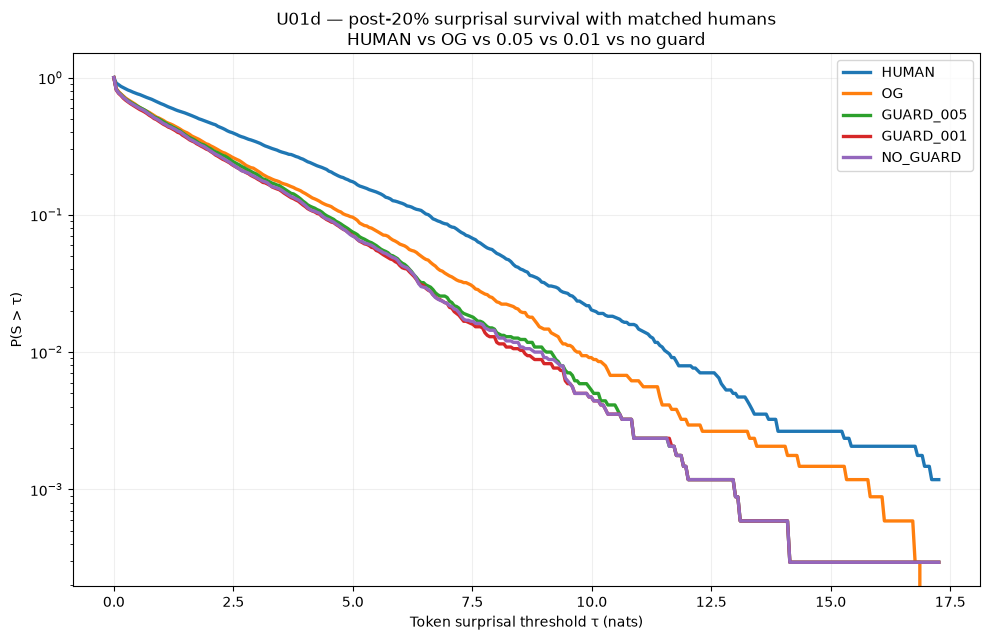

Saved: ../results/causal/U01d_unique_guard_ablation/guard_ablation_post20pct_with_matched_human.png


In [13]:
# ============================================================
# U01d — add the CORRESPONDING matched human to the guard plot
#
# Comparison:
#   HUMAN (matched per case)
#   OG
#   GUARD_005
#   GUARD_001
#   NO_GUARD
#
# Same protocol as before:
#   - same Qwen scorer
#   - same 20 cases
#   - discard first 20% of each case's OG scorer-token length
#   - use COMMON matched support across all 5 conditions
# ============================================================

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from IPython.display import display

assert "score_df" in globals()
assert "paired" in globals()
assert "og_panel" in globals()
assert "stok" in globals() and "smodel" in globals()
assert "SCORE_CACHE" in globals()

HUMAN_SPLIT_PATH = (
    ROOT
    / "results/causal/C02w_adaptive_camouflage_v1/split.csv"
)

assert HUMAN_SPLIT_PATH.exists(), HUMAN_SPLIT_PATH

split = pd.read_csv(HUMAN_SPLIT_PATH)

split["case_id"] = split["case_id"].astype(str)

human_map = (
    split[
        [
            "case_id",
            "human_source_id",
            "human_domain",
        ]
    ]
    .drop_duplicates("case_id")
    .set_index("case_id")
)

# Exact human text lookup from paired corpus.
human_text_lookup = (
    paired
    .drop_duplicates("source_id")
    .set_index("source_id")["text"]
    .to_dict()
)

human_jobs = []

for r in og_panel.itertuples(index=False):

    cid = str(r.case_id)

    assert cid in human_map.index, cid

    human_sid = str(
        human_map.loc[
            cid,
            "human_source_id",
        ]
    )

    assert human_sid in human_text_lookup, (
        cid,
        human_sid,
    )

    human_jobs.append(
        (
            cid,
            human_sid,
            str(human_text_lookup[human_sid]),
        )
    )

print("Matched human texts:", len(human_jobs))
assert len(human_jobs) == 20


# ------------------------------------------------------------
# 1. Score the 20 matched human texts.
# ------------------------------------------------------------

done = set(
    zip(
        score_df["case_id"].astype(str),
        score_df["condition"].astype(str),
    )
)

for cid, human_sid, text in tqdm(
    human_jobs,
    desc="Scoring matched humans",
):

    if (cid, "HUMAN") in done:
        continue

    ids_all = stok(
        text,
        add_special_tokens=False,
    )["input_ids"]

    n_total = len(ids_all)

    ids = ids_all[:MAX_COMPARE_TOKENS]

    assert len(ids) >= 2, (
        cid,
        "HUMAN",
        len(ids),
    )

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )

    with torch.inference_mode():

        output = smodel(
            input_ids=x,
            use_cache=False,
        )

        logits = output.logits[:, :-1, :]
        targets = x[:, 1:]

        ce = F.cross_entropy(
            logits.reshape(
                -1,
                logits.shape[-1],
            ).float(),
            targets.reshape(-1),
            reduction="none",
        )

    losses_np = (
        ce.detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    row = pd.DataFrame([{
        "case_id": cid,
        "condition": "HUMAN",
        "n_scorer_tokens": n_total,
        "losses": losses_np.tolist(),
    }])

    score_df = pd.concat(
        [score_df, row],
        ignore_index=True,
    )

    score_df.to_parquet(
        SCORE_CACHE,
        index=False,
    )

    done.add(
        (cid, "HUMAN")
    )

    del x, output, logits, targets, ce, losses_np

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 2. Rebuild lookup including HUMAN.
# ------------------------------------------------------------

loss_lookup_h = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    np.asarray(
        r.losses,
        dtype=float,
    )

    for r in score_df.itertuples(index=False)
}

len_lookup_h = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    int(r.n_scorer_tokens)

    for r in score_df.itertuples(index=False)
}


CONDITIONS_H = [
    "HUMAN",
    "OG",
    "GUARD_005",
    "GUARD_001",
    "NO_GUARD",
]


# ------------------------------------------------------------
# 3. Common matched support across ALL FIVE conditions.
#
# The cut is still defined by OG:
#
#   cut_i = ceil(.20 * OG_total_tokens)
#
# HUMAN does not get its own cut; we compare the same absolute
# post-warmup scorer-token positions across the matched case.
# ------------------------------------------------------------

suffixes_h = {
    cond: []
    for cond in CONDITIONS_H
}

support_rows_h = []

for cid in og_panel[
    "case_id"
].astype(str):

    per_case = {
        cond:
            loss_lookup_h[
                (cid, cond)
            ]

        for cond in CONDITIONS_H
    }

    # Everybody must contribute to exactly the same prefix support.
    m = min(
        len(v)
        for v in per_case.values()
    )

    og_total = len_lookup_h[
        (cid, "OG")
    ]

    cut_token = int(
        np.ceil(
            POST_CUT_FRACTION
            * og_total
        )
    )

    if cut_token >= m:
        continue

    for cond in CONDITIONS_H:
        suffixes_h[cond].append(
            per_case[cond][
                cut_token:m
            ]
        )

    support_rows_h.append({
        "case_id": cid,

        "human_total_tokens":
            len_lookup_h[
                (cid, "HUMAN")
            ],

        "OG_total_tokens":
            og_total,

        "cut_token_20pct":
            cut_token,

        "matched_end_token":
            m,

        "post_cut_positions":
            m - cut_token,
    })


support_h = pd.DataFrame(
    support_rows_h
)

print(
    "Cases surviving HUMAN + OG + 3-arm support:",
    len(support_h),
    "/ 20",
)

display(support_h)

assert len(support_h) > 0


# ------------------------------------------------------------
# 4. Aggregate distributions.
# ------------------------------------------------------------

agg_h = {
    cond:
        np.concatenate(
            suffixes_h[cond]
        )

    for cond in CONDITIONS_H
}


def _summary_h(x):

    x = np.asarray(
        x,
        float,
    )

    return {
        "n": len(x),

        "mean":
            np.mean(x),

        "median":
            np.median(x),

        "q75":
            np.quantile(x, .75),

        "q90":
            np.quantile(x, .90),

        "q95":
            np.quantile(x, .95),

        "q99":
            np.quantile(x, .99),
    }


summary_h = pd.DataFrame([
    {
        "condition": cond,
        **_summary_h(
            agg_h[cond]
        ),
    }
    for cond in CONDITIONS_H
]).set_index("condition")

print(
    "\nPost-20% matched-human surprisal summary:"
)

display(summary_h)


# ------------------------------------------------------------
# 5. Tail-frequency comparison.
# ------------------------------------------------------------

TAILS_H = [
    4,
    6,
    8,
    10,
]

tail_rows_h = []

for cond in CONDITIONS_H:

    x = agg_h[cond]

    for tau in TAILS_H:

        mask = x > tau

        tail_rows_h.append({
            "condition": cond,
            "tau": tau,

            "P_S_gt_tau":
                float(
                    mask.mean()
                ),

            "E_S_given_tail":
                float(
                    x[mask].mean()
                    if mask.any()
                    else np.nan
                ),
        })


tail_h = pd.DataFrame(
    tail_rows_h
)

print(
    "\nPost-20% matched-human tail frequencies:"
)

display(
    tail_h.pivot(
        index="tau",
        columns="condition",
        values=[
            "P_S_gt_tau",
            "E_S_given_tail",
        ],
    )
)


# ------------------------------------------------------------
# 6. Survival plot including matched HUMAN.
# ------------------------------------------------------------

xmax_h = min(
    20.0,
    max(
        np.quantile(
            x,
            .999,
        )
        for x in agg_h.values()
    ),
)

taus_h = np.linspace(
    0,
    xmax_h,
    350,
)

survival_h = {
    cond:
        np.array([
            np.mean(
                agg_h[cond] > tau
            )
            for tau in taus_h
        ])

    for cond in CONDITIONS_H
}


fig, ax = plt.subplots(
    figsize=(10, 6.5)
)

for cond in CONDITIONS_H:

    ax.plot(
        taus_h,
        survival_h[cond],
        linewidth=2.4,
        label=cond,
    )


ax.set_yscale("log")

ax.set_xlabel(
    "Token surprisal threshold τ (nats)"
)

ax.set_ylabel(
    "P(S > τ)"
)

ax.set_title(
    "U01d — post-20% surprisal survival with matched humans\n"
    "HUMAN vs OG vs 0.05 vs 0.01 vs no guard"
)

ax.grid(alpha=.2)
ax.legend()

fig.tight_layout()

PLOT_H = (
    OUT
    / "guard_ablation_post20pct_with_matched_human.png"
)

fig.savefig(
    PLOT_H,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", PLOT_H)

In [14]:
# ============================================================
# U01d — 20-case plain Llama regeneration baseline
#
# Condition:
#   Llama-3.2-3B-Instruct
#   + same WITH_PREV prompt
#   + FULL self-history
#   + greedy decoding
#   + NO Unique intervention
#   + NO likelihood guard
#
# This isolates the effect of regeneration/model from Unique.
# ============================================================

from pathlib import Path
import gc
import hashlib
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# 1. Free the Qwen scorer and restore the generator.
# ------------------------------------------------------------

for name in ["smodel", "stok"]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

GEN_DTYPE = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)

MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"
MAX_NEW_TOKENS = 640

tok = AutoTokenizer.from_pretrained(
    MODEL_ID,
    use_fast=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=GEN_DTYPE,
    low_cpu_mem_usage=True,
).to(device).eval()

eos = model.generation_config.eos_token_id

if eos is None:
    eos = tok.eos_token_id

EOS_IDS = (
    list(eos)
    if isinstance(eos, (list, tuple))
    else [int(eos)]
)

# HF generate needs a pad token for batched/generative bookkeeping.
if tok.pad_token_id is None:
    tok.pad_token_id = tok.eos_token_id

print("Loaded generator:", MODEL_ID)


# ------------------------------------------------------------
# 2. Exact WITH_PREV prompt used in U01b/U01d.
# ------------------------------------------------------------

def build_messages_plain(prompt, previous_ai):
    content = (
        f"Original task:\n{prompt}\n\n"
        f"Previous AI answer:\n{previous_ai}\n\n"
        "Generate a fresh complete answer to the original task. "
        "Preserve the substantive content of the previous AI answer."
    )

    return [
        {
            "role": "user",
            "content": content,
        }
    ]


def prompt_tensor_plain(prompt, previous_ai):

    rendered = tok.apply_chat_template(
        build_messages_plain(
            prompt,
            previous_ai,
        ),
        tokenize=False,
        add_generation_prompt=True,
    )

    return tok(
        rendered,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"].to(device)


# ------------------------------------------------------------
# 3. Previous-AI lookup.
#
# cohort from U01d already contains previous_ai. Verify that
# before starting so we don't silently use another source.
# ------------------------------------------------------------

assert "cohort" in globals()
assert len(cohort) == 20
assert "previous_ai" in cohort.columns
assert "prompt" in cohort.columns


# ------------------------------------------------------------
# 4. Checkpoint setup.
# ------------------------------------------------------------

PLAIN_PATH = (
    OUT
    / "llama_withprev_full_no_unique_generations.parquet"
)

if PLAIN_PATH.exists():

    plain_gen = pd.read_parquet(
        PLAIN_PATH
    )

    # Failed attempts never count as completed.
    if "status" in plain_gen.columns:

        bad = plain_gen[
            "status"
        ].astype(str).eq(
            "failed_exception"
        )

        if bad.any():

            print(
                "Dropping failed rows:",
                int(bad.sum()),
            )

            plain_gen = (
                plain_gen.loc[~bad]
                .reset_index(drop=True)
            )

            plain_gen.to_parquet(
                PLAIN_PATH,
                index=False,
            )

else:

    plain_gen = pd.DataFrame()


done = (
    set(
        plain_gen[
            "case_id"
        ].astype(str)
    )
    if len(plain_gen)
    else set()
)


# ------------------------------------------------------------
# 5. Generate the 20 cases.
#
# Greedy decoding = direct ordinary argmax trajectory.
# No Unique controller or search functions are called.
# ------------------------------------------------------------

pbar = tqdm(
    total=len(cohort),
    initial=len(done),
    desc="Plain Llama / no Unique",
)

for src in cohort.itertuples(index=False):

    cid = str(src.case_id)

    if cid in done:
        continue

    try:

        input_ids = prompt_tensor_plain(
            src.prompt,
            src.previous_ai,
        )

        prompt_len = int(
            input_ids.shape[1]
        )

        with torch.inference_mode():

            generated = model.generate(
                input_ids=input_ids,

                do_sample=False,

                max_new_tokens=
                    MAX_NEW_TOKENS,

                eos_token_id=
                    EOS_IDS,

                pad_token_id=
                    tok.pad_token_id,

                use_cache=True,
            )

        new_ids = (
            generated[
                0,
                prompt_len:
            ]
            .detach()
            .cpu()
            .tolist()
        )

        text = tok.decode(
            new_ids,
            skip_special_tokens=True,
        )

        hit_eos = (
            len(new_ids) > 0
            and new_ids[-1]
            in set(EOS_IDS)
        )

        if hit_eos:
            status = "completed_eos"
            stop_reason = "eos"

        elif len(new_ids) >= MAX_NEW_TOKENS:
            status = "truncated_token_cap"
            stop_reason = "truncated"

        else:
            status = "completed_other"
            stop_reason = "other"


        row = {
            "case_id": cid,
            "source_id": src.source_id,
            "domain": src.domain,

            "condition":
                "LLAMA_NO_UNIQUE",

            "model_id":
                MODEL_ID,

            "with_prev":
                True,

            "temporal_method":
                "FULL",

            "unique_control":
                False,

            "guard_enabled":
                False,

            "generated_text":
                text,

            "generator_tokens":
                len(new_ids),

            "status":
                status,

            "stop_reason":
                stop_reason,

            "text_sha":
                hashlib.sha256(
                    text.encode()
                ).hexdigest(),
        }


    except Exception as e:

        row = {
            "case_id": cid,
            "source_id": src.source_id,
            "domain": src.domain,

            "condition":
                "LLAMA_NO_UNIQUE",

            "model_id":
                MODEL_ID,

            "with_prev":
                True,

            "temporal_method":
                "FULL",

            "unique_control":
                False,

            "guard_enabled":
                False,

            "generated_text":
                "",

            "generator_tokens":
                0,

            "status":
                "failed_exception",

            "stop_reason":
                "exception",

            "exception":
                repr(e),

            "text_sha":
                None,
        }


    plain_gen = pd.concat(
        [
            plain_gen,
            pd.DataFrame([row]),
        ],
        ignore_index=True,
    )

    plain_gen.to_parquet(
        PLAIN_PATH,
        index=False,
    )

    pbar.update(1)

    if row["status"] == "failed_exception":

        pbar.close()

        raise RuntimeError(
            f"{cid} failed: "
            f"{row.get('exception')}"
        )

    done.add(cid)

    del input_ids

    if "generated" in locals():
        del generated

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


pbar.close()



Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 254/254 [00:00<00:00, 417.78it/s]


Loaded generator: meta-llama/Llama-3.2-3B-Instruct


Plain Llama / no Unique: 100%|██████████████████████████████████████████████████████████████████████████| 20/20 [04:40<00:00, 14.02s/it]


Saved: ../results/causal/U01d_unique_guard_ablation/llama_withprev_full_no_unique_generations.parquet


ValueError: cannot reindex on an axis with duplicate labels

In [15]:
# U01d patch — summarize completed plain-Llama baseline
# Generation already finished; this only reads/summarizes plain_gen.

assert len(plain_gen) == 20
assert plain_gen["case_id"].is_unique
assert not plain_gen["status"].eq("failed_exception").any()

summary = pd.DataFrame([{
    "n": len(plain_gen),

    "eos": int(
        plain_gen["stop_reason"]
        .eq("eos")
        .sum()
    ),

    "truncated": int(
        plain_gen["stop_reason"]
        .eq("truncated")
        .sum()
    ),

    "mean_tokens": float(
        plain_gen["generator_tokens"]
        .mean()
    ),

    "median_tokens": float(
        plain_gen["generator_tokens"]
        .median()
    ),
}])

print("Saved:", PLAIN_PATH)
display(summary)

Saved: ../results/causal/U01d_unique_guard_ablation/llama_withprev_full_no_unique_generations.parquet


,n,eos,truncated,mean_tokens,median_tokens
0,20,19,1,368.95,394.0


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 3100.13it/s]


Loaded scorer: Qwen/Qwen3-0.6B-Base
Existing scored rows: 100


Scoring LLAMA_NO_UNIQUE: 100%|██████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 27.43it/s]

Cases surviving six-way support: 20 / 20


,case_id,cut_20pct_OG,matched_end,n_post_cut
0,gate_0090,46,206,160
1,gate_0070,54,255,201
2,gate_0017,79,255,176
3,gate_0085,60,255,195
4,gate_0038,29,141,112
5,gate_0039,42,206,164
6,gate_0069,26,128,102
7,gate_0035,53,255,202
8,gate_0003,86,255,169
9,gate_0025,69,255,186



Six-way post-20% surprisal summary:


,n,mean,median,q75,q90,q95,q99
condition,,,,,,,
HUMAN,3400,2.647980,1.786122,3.990723,6.588375,8.121027,11.552601
OG,3400,1.799237,0.972814,2.606926,4.847604,6.408674,9.670381
LLAMA_NO_UNIQUE,3400,1.676410,0.906306,2.475433,4.518834,5.962885,9.214464
GUARD_005,3400,1.660882,0.939354,2.447556,4.410323,5.841796,9.043562
GUARD_001,3400,1.586677,0.853122,2.319350,4.310344,5.671769,8.567214
NO_GUARD,3400,1.611528,0.890238,2.334922,4.341691,5.777686,8.756140


P_S_gt_tau                                                          \
condition  GUARD_001 GUARD_005     HUMAN LLAMA_NO_UNIQUE  NO_GUARD        OG   
tau                                                                            
4           0.115588  0.123235  0.249412        0.128824  0.117941  0.142941   
6           0.041765  0.045000  0.122059        0.048235  0.043235  0.060882   
8           0.012059  0.013824  0.053235        0.015882  0.013529  0.023529   
10          0.004706  0.005294  0.020294        0.006176  0.004706  0.009118   

          E_S_given_tail                                                   \
condition      GUARD_001  GUARD_005      HUMAN LLAMA_NO_UNIQUE   NO_GUARD   
tau                                                                         
4               5.896898   5.920628   6.570142        5.979472   5.900257   
6               7.734454   7.775169   8.345252        7.828767   7.734929   
8              10.106493  10.094071  10.174912        9.985804   9.983989   
10             11.897832  11.740437  12.366088       11.574668  11.894819   

                      
condition         OG  
tau                   
4           6.257867  
6           8.125570  
8          10.175108  
10         12.197441

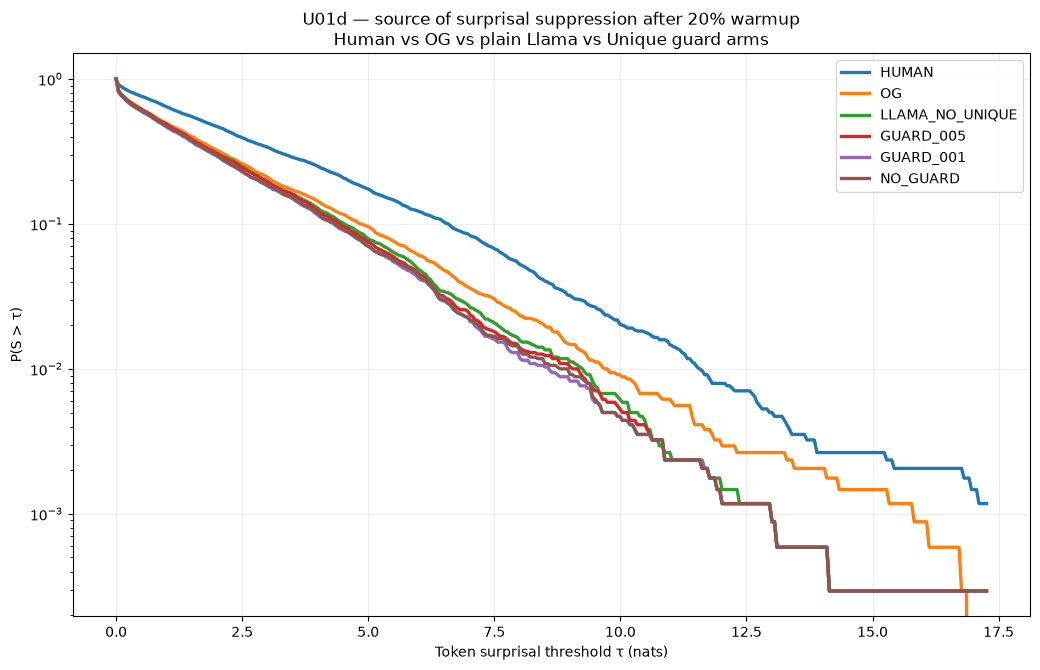

Saved: ../results/causal/U01d_unique_guard_ablation/surprisal_human_og_plain_llama_unique.png


In [17]:
# ============================================================
# U01d — final surprisal comparison
#
# HUMAN
# OG
# LLAMA_NO_UNIQUE
# GUARD_005
# GUARD_001
# NO_GUARD
#
# Same protocol:
#   - Qwen/Qwen3-0.6B-Base scorer
#   - case-specific cut = first 20% of OG scorer-token length
#   - common matched support across ALL SIX conditions
# ============================================================

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# 1. Free Llama; reload frozen Qwen scorer.
# ------------------------------------------------------------

for name in ["model", "tok"]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SCORER_ID = "Qwen/Qwen3-0.6B-Base"

scorer_dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)

stok = AutoTokenizer.from_pretrained(
    SCORER_ID,
    use_fast=True,
)

smodel = AutoModelForCausalLM.from_pretrained(
    SCORER_ID,
    dtype=scorer_dtype,
    low_cpu_mem_usage=True,
).to(device).eval()

print("Loaded scorer:", SCORER_ID)


# ------------------------------------------------------------
# 2. Recover existing score cache.
#
# This already contains:
#   HUMAN
#   OG
#   GUARD_005
#   GUARD_001
#   NO_GUARD
# ------------------------------------------------------------

assert "SCORE_CACHE" in globals()

score_df = pd.read_parquet(
    SCORE_CACHE
)

done = set(
    zip(
        score_df["case_id"].astype(str),
        score_df["condition"].astype(str),
    )
)

print(
    "Existing scored rows:",
    len(score_df),
)


# ------------------------------------------------------------
# 3. Score ONLY LLAMA_NO_UNIQUE.
# ------------------------------------------------------------

assert len(plain_gen) == 20
assert plain_gen["case_id"].is_unique

for r in tqdm(
    plain_gen.itertuples(index=False),
    total=len(plain_gen),
    desc="Scoring LLAMA_NO_UNIQUE",
):

    cid = str(r.case_id)

    if (cid, "LLAMA_NO_UNIQUE") in done:
        continue

    text = str(r.generated_text)

    ids_all = stok(
        text,
        add_special_tokens=False,
    )["input_ids"]

    n_total = len(ids_all)

    ids = ids_all[
        :MAX_COMPARE_TOKENS
    ]

    assert len(ids) >= 2, (
        cid,
        len(ids),
    )

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )

    with torch.inference_mode():

        out = smodel(
            input_ids=x,
            use_cache=False,
        )

        logits = out.logits[
            :, :-1, :
        ]

        targets = x[:, 1:]

        ce = F.cross_entropy(
            logits.reshape(
                -1,
                logits.shape[-1],
            ).float(),
            targets.reshape(-1),
            reduction="none",
        )

    losses = (
        ce.detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    score_df = pd.concat(
        [
            score_df,
            pd.DataFrame([{
                "case_id": cid,
                "condition":
                    "LLAMA_NO_UNIQUE",

                "n_scorer_tokens":
                    n_total,

                "losses":
                    losses.tolist(),
            }]),
        ],
        ignore_index=True,
    )

    score_df.to_parquet(
        SCORE_CACHE,
        index=False,
    )

    done.add(
        (cid, "LLAMA_NO_UNIQUE")
    )

    del x, out, logits, targets, ce, losses

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 4. Rebuild lookup.
# ------------------------------------------------------------

loss_lookup_final = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    np.asarray(
        r.losses,
        dtype=float,
    )

    for r in score_df.itertuples(
        index=False
    )
}

length_lookup_final = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    int(r.n_scorer_tokens)

    for r in score_df.itertuples(
        index=False
    )
}


CONDITIONS_FINAL = [
    "HUMAN",
    "OG",
    "LLAMA_NO_UNIQUE",
    "GUARD_005",
    "GUARD_001",
    "NO_GUARD",
]


# ------------------------------------------------------------
# 5. Common matched post-20% support across ALL SIX arms.
# ------------------------------------------------------------

suffixes_final = {
    c: []
    for c in CONDITIONS_FINAL
}

support_final_rows = []

for cid in og_panel[
    "case_id"
].astype(str):

    per_case = {
        c:
            loss_lookup_final[
                (cid, c)
            ]

        for c in CONDITIONS_FINAL
    }

    # Everyone gets exactly the same token-position support.
    m = min(
        len(x)
        for x in per_case.values()
    )

    og_total = (
        length_lookup_final[
            (cid, "OG")
        ]
    )

    cut = int(
        np.ceil(
            POST_CUT_FRACTION
            * og_total
        )
    )

    if cut >= m:
        continue

    for c in CONDITIONS_FINAL:

        suffixes_final[c].append(
            per_case[c][cut:m]
        )

    support_final_rows.append({
        "case_id": cid,
        "cut_20pct_OG": cut,
        "matched_end": m,
        "n_post_cut": m - cut,
    })


support_final = pd.DataFrame(
    support_final_rows
)

print(
    "Cases surviving six-way support:",
    len(support_final),
    "/ 20",
)

display(support_final)


# ------------------------------------------------------------
# 6. Aggregate.
# ------------------------------------------------------------

agg_final = {
    c:
        np.concatenate(
            suffixes_final[c]
        )

    for c in CONDITIONS_FINAL
}


summary_final = []

for c in CONDITIONS_FINAL:

    x = agg_final[c]

    summary_final.append({
        "condition": c,
        "n": len(x),
        "mean": x.mean(),
        "median": np.median(x),
        "q75": np.quantile(x, .75),
        "q90": np.quantile(x, .90),
        "q95": np.quantile(x, .95),
        "q99": np.quantile(x, .99),
    })


summary_final = (
    pd.DataFrame(
        summary_final
    )
    .set_index("condition")
)

print(
    "\nSix-way post-20% surprisal summary:"
)

display(summary_final)


# ------------------------------------------------------------
# 7. Tail frequencies.
# ------------------------------------------------------------

TAILS = [
    4,
    6,
    8,
    10,
]

tail_rows = []

for c in CONDITIONS_FINAL:

    x = agg_final[c]

    for tau in TAILS:

        mask = x > tau

        tail_rows.append({
            "condition": c,
            "tau": tau,

            "P_S_gt_tau":
                float(
                    mask.mean()
                ),

            "E_S_given_tail":
                float(
                    x[mask].mean()
                    if mask.any()
                    else np.nan
                ),
        })


tail_final = pd.DataFrame(
    tail_rows
)

display(
    tail_final.pivot(
        index="tau",
        columns="condition",
        values=[
            "P_S_gt_tau",
            "E_S_given_tail",
        ],
    )
)


# ------------------------------------------------------------
# 8. Survival graph.
# ------------------------------------------------------------

xmax = min(
    20.0,
    max(
        np.quantile(
            x,
            .999,
        )
        for x in agg_final.values()
    ),
)

taus = np.linspace(
    0,
    xmax,
    350,
)

fig, ax = plt.subplots(
    figsize=(10.5, 6.8)
)

for c in CONDITIONS_FINAL:

    survival = np.array([
        np.mean(
            agg_final[c] > tau
        )
        for tau in taus
    ])

    ax.plot(
        taus,
        survival,
        linewidth=2.4,
        label=c,
    )


ax.set_yscale("log")

ax.set_xlabel(
    "Token surprisal threshold τ (nats)"
)

ax.set_ylabel(
    "P(S > τ)"
)

ax.set_title(
    "U01d — source of surprisal suppression after 20% warmup\n"
    "Human vs OG vs plain Llama vs Unique guard arms"
)

ax.grid(alpha=.2)
ax.legend()

fig.tight_layout()

FINAL_PLOT = (
    OUT
    / "surprisal_human_og_plain_llama_unique.png"
)

fig.savefig(
    FINAL_PLOT,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    FINAL_PLOT,
)

In [ ]:
# ============================================================
# U01d — decoding-policy ablation, NO Unique
#
# Existing baseline:
#   LLAMA_NO_UNIQUE = greedy / argmax
#
# New arms:
#   SAMPLE_T07       : temperature=.7, top_p=1.0
#   SAMPLE_T10       : temperature=1.0, top_p=1.0
#   SAMPLE_T10_P09   : temperature=1.0, top_p=.90
#
# Everything else frozen:
#   - Llama-3.2-3B-Instruct
#   - same WITH_PREV prompt
#   - no Unique
#   - no guard
#   - max_new_tokens=640
#
# Seeds are deterministic per case × arm so the experiment is
# exactly reproducible.
# ============================================================

import gc
import hashlib
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# 1. Free scorer and restore Llama.
# ------------------------------------------------------------

for name in ["smodel", "stok"]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

GEN_DTYPE = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)

MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"
MAX_NEW_TOKENS = 640

tok = AutoTokenizer.from_pretrained(
    MODEL_ID,
    use_fast=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=GEN_DTYPE,
    low_cpu_mem_usage=True,
).to(device).eval()

if tok.pad_token_id is None:
    tok.pad_token_id = tok.eos_token_id

eos = model.generation_config.eos_token_id

if eos is None:
    eos = tok.eos_token_id

EOS_IDS = (
    list(eos)
    if isinstance(eos, (list, tuple))
    else [int(eos)]
)

print("Loaded generator:", MODEL_ID)


# ------------------------------------------------------------
# 2. Same WITH_PREV prompt as the greedy baseline.
# ------------------------------------------------------------

def build_messages_sampling(prompt, previous_ai):

    content = (
        f"Original task:\n{prompt}\n\n"
        f"Previous AI answer:\n{previous_ai}\n\n"
        "Generate a fresh complete answer to the original task. "
        "Preserve the substantive content of the previous AI answer."
    )

    return [{
        "role": "user",
        "content": content,
    }]


def prompt_tensor_sampling(prompt, previous_ai):

    rendered = tok.apply_chat_template(
        build_messages_sampling(
            prompt,
            previous_ai,
        ),
        tokenize=False,
        add_generation_prompt=True,
    )

    return tok(
        rendered,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"].to(device)


# ------------------------------------------------------------
# 3. Decoding arms.
#
# These isolate:
#
#   temperature:
#       T=.7 vs T=1.0 with full support
#
#   nucleus truncation:
#       T=1.0 full support vs top_p=.90
# ------------------------------------------------------------

SAMPLING_ARMS = {
    "SAMPLE_T07": {
        "temperature": 0.7,
        "top_p": 1.0,
    },

    "SAMPLE_T10": {
        "temperature": 1.0,
        "top_p": 1.0,
    },

    "SAMPLE_T10_P09": {
        "temperature": 1.0,
        "top_p": 0.90,
    },
}


# ------------------------------------------------------------
# 4. Deterministic per-case × arm seed.
# ------------------------------------------------------------

def experiment_seed(case_id, arm):

    key = (
        f"U01d|{case_id}|{arm}|20260916"
        .encode()
    )

    h = hashlib.sha256(key).digest()

    return int.from_bytes(
        h[:4],
        byteorder="little",
        signed=False,
    )


# ------------------------------------------------------------
# 5. Checkpoint.
# ------------------------------------------------------------

SAMPLE_PATH = (
    OUT
    / "llama_no_unique_sampling_ablation.parquet"
)

if SAMPLE_PATH.exists():

    sample_gen = pd.read_parquet(
        SAMPLE_PATH
    )

    if "status" in sample_gen.columns:

        failed = (
            sample_gen["status"]
            .astype(str)
            .eq("failed_exception")
        )

        if failed.any():

            print(
                "Dropping failed checkpoint rows:",
                int(failed.sum()),
            )

            sample_gen = (
                sample_gen.loc[~failed]
                .reset_index(drop=True)
            )

            sample_gen.to_parquet(
                SAMPLE_PATH,
                index=False,
            )

else:

    sample_gen = pd.DataFrame()


if len(sample_gen):

    done = set(
        zip(
            sample_gen["case_id"].astype(str),
            sample_gen["decoding_arm"].astype(str),
        )
    )

else:

    done = set()


assert len(cohort) == 20
assert "prompt" in cohort.columns
assert "previous_ai" in cohort.columns

total = (
    len(cohort)
    * len(SAMPLING_ARMS)
)

pbar = tqdm(
    total=total,
    initial=len(done),
    desc="Llama sampling / no Unique",
)


# ------------------------------------------------------------
# 6. Generate 20 × 3 = 60 texts.
# ------------------------------------------------------------

for src in cohort.itertuples(index=False):

    cid = str(src.case_id)

    input_ids = prompt_tensor_sampling(
        src.prompt,
        src.previous_ai,
    )

    prompt_len = int(
        input_ids.shape[1]
    )

    for arm, cfg in SAMPLING_ARMS.items():

        if (cid, arm) in done:
            continue

        seed = experiment_seed(
            cid,
            arm,
        )

        generator = torch.Generator(
            device=device
        )

        generator.manual_seed(seed)

        try:

            with torch.inference_mode():

                generated = model.generate(
                    input_ids=input_ids,

                    do_sample=True,

                    temperature=float(
                        cfg["temperature"]
                    ),

                    top_p=float(
                        cfg["top_p"]
                    ),

                    max_new_tokens=
                        MAX_NEW_TOKENS,

                    eos_token_id=
                        EOS_IDS,

                    pad_token_id=
                        tok.pad_token_id,

                    use_cache=True,

                    generator=generator,
                )

            new_ids = (
                generated[
                    0,
                    prompt_len:
                ]
                .detach()
                .cpu()
                .tolist()
            )

            text = tok.decode(
                new_ids,
                skip_special_tokens=True,
            )

            hit_eos = (
                len(new_ids) > 0
                and new_ids[-1]
                in set(EOS_IDS)
            )

            if hit_eos:

                status = "completed_eos"
                stop_reason = "eos"

            elif (
                len(new_ids)
                >= MAX_NEW_TOKENS
            ):

                status = (
                    "truncated_token_cap"
                )

                stop_reason = "truncated"

            else:

                status = "completed_other"
                stop_reason = "other"


            row = {
                "case_id": cid,
                "source_id":
                    src.source_id,

                "domain":
                    src.domain,

                "decoding_arm":
                    arm,

                "condition":
                    arm,

                "model_id":
                    MODEL_ID,

                "with_prev":
                    True,

                "temporal_method":
                    "FULL",

                "unique_control":
                    False,

                "guard_enabled":
                    False,

                "do_sample":
                    True,

                "temperature":
                    cfg["temperature"],

                "top_p":
                    cfg["top_p"],

                "seed":
                    seed,

                "generated_text":
                    text,

                "generator_tokens":
                    len(new_ids),

                "status":
                    status,

                "stop_reason":
                    stop_reason,

                "text_sha":
                    hashlib.sha256(
                        text.encode()
                    ).hexdigest(),
            }


        except Exception as e:

            row = {
                "case_id": cid,
                "source_id":
                    src.source_id,

                "domain":
                    src.domain,

                "decoding_arm":
                    arm,

                "condition":
                    arm,

                "model_id":
                    MODEL_ID,

                "with_prev":
                    True,

                "temporal_method":
                    "FULL",

                "unique_control":
                    False,

                "guard_enabled":
                    False,

                "do_sample":
                    True,

                "temperature":
                    cfg["temperature"],

                "top_p":
                    cfg["top_p"],

                "seed":
                    seed,

                "generated_text":
                    "",

                "generator_tokens":
                    0,

                "status":
                    "failed_exception",

                "stop_reason":
                    "exception",

                "exception":
                    repr(e),

                "text_sha":
                    None,
            }


        sample_gen = pd.concat(
            [
                sample_gen,
                pd.DataFrame([row]),
            ],
            ignore_index=True,
        )

        sample_gen.to_parquet(
            SAMPLE_PATH,
            index=False,
        )

        pbar.update(1)

        if row[
            "status"
        ] == "failed_exception":

            pbar.close()

            raise RuntimeError(
                f"{cid}/{arm} failed: "
                f"{row.get('exception')}"
            )

        done.add(
            (cid, arm)
        )

        if "generated" in locals():
            del generated

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    del input_ids


pbar.close()


# ------------------------------------------------------------
# 7. Validate + summarize.
# ------------------------------------------------------------

assert len(sample_gen) == 60, (
    len(sample_gen),
    60,
)

assert (
    sample_gen[
        ["case_id", "decoding_arm"]
    ]
    .drop_duplicates()
    .shape[0]
    == 60
)

assert not sample_gen[
    "status"
].eq(
    "failed_exception"
).any()


summary_sampling = (
    sample_gen
    .groupby("decoding_arm")
    .agg(
        n=(
            "case_id",
            "size",
        ),

        eos=(
            "stop_reason",
            lambda x:
                int(
                    (x == "eos").sum()
                ),
        ),

        truncated=(
            "stop_reason",
            lambda x:
                int(
                    (x == "truncated").sum()
                ),
        ),

        mean_tokens=(
            "generator_tokens",
            "mean",
        ),

        median_tokens=(
            "generator_tokens",
            "median",
        ),
    )
)

print(
    "Saved:",
    SAMPLE_PATH,
)

display(
    summary_sampling
)

In [19]:
# ============================================================
# U01d patch — resume sampling ablation without generator=
#
# Current Transformers/model.generate does not accept the
# `generator` kwarg. We instead seed Python/NumPy/Torch globally
# immediately before each generation.
#
# This:
#   1. removes the failed SAMPLE_T07 checkpoint row
#   2. keeps any successful rows
#   3. resumes the 20 × 3 experiment
# ============================================================

import random
import gc
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. Reload checkpoint and remove failed attempts.
# ------------------------------------------------------------

if SAMPLE_PATH.exists():

    sample_gen = pd.read_parquet(
        SAMPLE_PATH
    )

    if "status" in sample_gen.columns:

        failed = (
            sample_gen["status"]
            .astype(str)
            .eq("failed_exception")
        )

        if failed.any():

            print(
                "Dropping failed rows:",
                int(failed.sum()),
            )

            sample_gen = (
                sample_gen.loc[~failed]
                .reset_index(drop=True)
            )

            sample_gen.to_parquet(
                SAMPLE_PATH,
                index=False,
            )

else:

    sample_gen = pd.DataFrame()


if len(sample_gen):

    done = set(
        zip(
            sample_gen["case_id"].astype(str),
            sample_gen["decoding_arm"].astype(str),
        )
    )

else:

    done = set()


total = (
    len(cohort)
    * len(SAMPLING_ARMS)
)

print(
    "Already completed:",
    len(done),
    "/",
    total,
)


# ------------------------------------------------------------
# 2. Resume generation.
# ------------------------------------------------------------

pbar = tqdm(
    total=total,
    initial=len(done),
    desc="Llama sampling / no Unique",
)

for src in cohort.itertuples(index=False):

    cid = str(src.case_id)

    input_ids = prompt_tensor_sampling(
        src.prompt,
        src.previous_ai,
    )

    prompt_len = int(
        input_ids.shape[1]
    )

    for arm, cfg in SAMPLING_ARMS.items():

        if (cid, arm) in done:
            continue

        seed = experiment_seed(
            cid,
            arm,
        )

        # Deterministic per-case × arm RNG state.
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        try:

            with torch.inference_mode():

                generated = model.generate(
                    input_ids=input_ids,

                    do_sample=True,

                    temperature=float(
                        cfg["temperature"]
                    ),

                    top_p=float(
                        cfg["top_p"]
                    ),

                    max_new_tokens=
                        MAX_NEW_TOKENS,

                    eos_token_id=
                        EOS_IDS,

                    pad_token_id=
                        tok.pad_token_id,

                    use_cache=True,

                    # IMPORTANT:
                    # no generator= argument
                )

            new_ids = (
                generated[
                    0,
                    prompt_len:
                ]
                .detach()
                .cpu()
                .tolist()
            )

            text = tok.decode(
                new_ids,
                skip_special_tokens=True,
            )

            hit_eos = (
                len(new_ids) > 0
                and new_ids[-1]
                in set(EOS_IDS)
            )

            if hit_eos:

                status = "completed_eos"
                stop_reason = "eos"

            elif (
                len(new_ids)
                >= MAX_NEW_TOKENS
            ):

                status = "truncated_token_cap"
                stop_reason = "truncated"

            else:

                status = "completed_other"
                stop_reason = "other"


            row = {
                "case_id": cid,
                "source_id":
                    src.source_id,

                "domain":
                    src.domain,

                "decoding_arm":
                    arm,

                "condition":
                    arm,

                "model_id":
                    MODEL_ID,

                "with_prev":
                    True,

                "temporal_method":
                    "FULL",

                "unique_control":
                    False,

                "guard_enabled":
                    False,

                "do_sample":
                    True,

                "temperature":
                    cfg["temperature"],

                "top_p":
                    cfg["top_p"],

                "seed":
                    seed,

                "generated_text":
                    text,

                "generator_tokens":
                    len(new_ids),

                "status":
                    status,

                "stop_reason":
                    stop_reason,

                "text_sha":
                    hashlib.sha256(
                        text.encode()
                    ).hexdigest(),
            }


        except Exception as e:

            row = {
                "case_id": cid,
                "source_id":
                    src.source_id,

                "domain":
                    src.domain,

                "decoding_arm":
                    arm,

                "condition":
                    arm,

                "model_id":
                    MODEL_ID,

                "with_prev":
                    True,

                "temporal_method":
                    "FULL",

                "unique_control":
                    False,

                "guard_enabled":
                    False,

                "do_sample":
                    True,

                "temperature":
                    cfg["temperature"],

                "top_p":
                    cfg["top_p"],

                "seed":
                    seed,

                "generated_text":
                    "",

                "generator_tokens":
                    0,

                "status":
                    "failed_exception",

                "stop_reason":
                    "exception",

                "exception":
                    repr(e),

                "text_sha":
                    None,
            }


        sample_gen = pd.concat(
            [
                sample_gen,
                pd.DataFrame([row]),
            ],
            ignore_index=True,
        )

        sample_gen.to_parquet(
            SAMPLE_PATH,
            index=False,
        )

        pbar.update(1)

        if row["status"] == "failed_exception":

            pbar.close()

            raise RuntimeError(
                f"{cid}/{arm} failed: "
                f"{row.get('exception')}"
            )

        done.add(
            (cid, arm)
        )

        if "generated" in locals():
            del generated

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    del input_ids


pbar.close()


# ------------------------------------------------------------
# 3. Validate + summarize.
# ------------------------------------------------------------

assert len(sample_gen) == 60, (
    len(sample_gen),
    60,
)

assert (
    sample_gen[
        ["case_id", "decoding_arm"]
    ]
    .drop_duplicates()
    .shape[0]
    == 60
)

assert not sample_gen[
    "status"
].eq(
    "failed_exception"
).any()


summary_sampling = (
    sample_gen
    .groupby("decoding_arm")
    .agg(
        n=(
            "case_id",
            "size",
        ),

        eos=(
            "stop_reason",
            lambda x:
                int(
                    (x == "eos").sum()
                ),
        ),

        truncated=(
            "stop_reason",
            lambda x:
                int(
                    (x == "truncated").sum()
                ),
        ),

        mean_tokens=(
            "generator_tokens",
            "mean",
        ),

        median_tokens=(
            "generator_tokens",
            "median",
        ),
    )
)

print("Saved:", SAMPLE_PATH)

display(summary_sampling)

Dropping failed rows: 1
Already completed: 0 / 60


Llama sampling / no Unique: 100%|███████████████████████████████████████████████████████████████████████| 60/60 [14:46<00:00, 14.77s/it]

Saved: ../results/causal/U01d_unique_guard_ablation/llama_no_unique_sampling_ablation.parquet


,n,eos,truncated,mean_tokens,median_tokens
decoding_arm,,,,,
SAMPLE_T07,20,19,1,412.15,422.0
SAMPLE_T10,20,20,0,399.75,426.0
SAMPLE_T10_P09,20,19,1,397.05,390.5


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 3237.75it/s]


Loaded scorer: Qwen/Qwen3-0.6B-Base


Scoring sampling arms: 100%|████████████████████████████████████████████████████████████████████████████| 60/60 [00:02<00:00, 27.23it/s]

Cases surviving six-way support: 20 / 20


,case_id,cut_20pct_OG,matched_end,n_post_cut
0,gate_0090,46,210,164
1,gate_0070,54,255,201
2,gate_0017,79,255,176
3,gate_0085,60,255,195
4,gate_0038,29,141,112
5,gate_0039,42,206,164
6,gate_0069,26,128,102
7,gate_0035,53,255,202
8,gate_0003,86,255,169
9,gate_0025,69,255,186



Decoding-policy post-20% surprisal summary:


,n,mean,median,q75,q90,q95,q99
condition,,,,,,,
HUMAN,3454,2.637328,1.770739,3.978040,6.569546,8.122826,11.516455
OG,3454,1.797093,0.964912,2.602115,4.858888,6.415319,9.754504
LLAMA_NO_UNIQUE,3454,1.667899,0.902823,2.467639,4.501637,5.955134,9.184447
SAMPLE_T07,3454,1.654616,0.919016,2.416088,4.475594,5.996150,8.828838
SAMPLE_T10,3454,1.769826,0.983381,2.607978,4.811315,6.140716,9.294262
SAMPLE_T10_P09,3454,1.602619,0.835720,2.359089,4.413662,5.756483,8.647551


P_S_gt_tau                                                  \
condition      HUMAN LLAMA_NO_UNIQUE        OG SAMPLE_T07 SAMPLE_T10   
tau                                                                    
4           0.248118        0.127389  0.142733   0.124783   0.139548   
6           0.121309        0.047771  0.061089   0.049797   0.054430   
8           0.053272        0.015634  0.023741   0.016213   0.020266   
10          0.020266        0.006080  0.009554   0.005211   0.006369   

                         E_S_given_tail                                        \
condition SAMPLE_T10_P09          HUMAN LLAMA_NO_UNIQUE         OG SAMPLE_T07   
tau                                                                             
4               0.120730       6.574579        5.980655   6.272808   6.006301   
6               0.041980       8.352565        7.822215   8.142471   7.696866   
8               0.013318      10.167109        9.985804  10.199038   9.718661   
10              0.003764      12.350996       11.574668  12.134338  11.572739   

                                     
condition SAMPLE_T10 SAMPLE_T10_P09  
tau                                  
4           6.061463       5.900852  
6           7.831212       7.718267  
8           9.698159       9.788209  
10         11.577569      12.022471

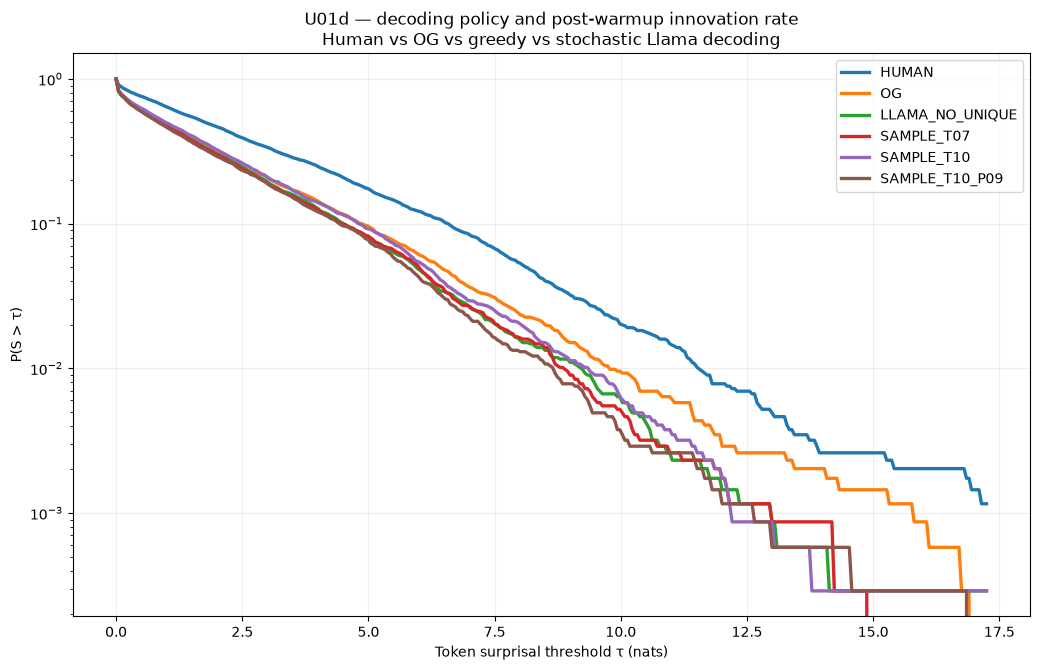

Saved: ../results/causal/U01d_unique_guard_ablation/decoding_ablation_post20pct_surprisal.png


In [20]:
# ============================================================
# U01d — decoding-policy surprisal comparison
#
# HUMAN
# OG
# LLAMA_NO_UNIQUE       = greedy
# SAMPLE_T07
# SAMPLE_T10
# SAMPLE_T10_P09
#
# Same protocol:
#   - Qwen/Qwen3-0.6B-Base frozen scorer
#   - discard first 20% of each case's OG scorer-token length
#   - common matched support across ALL SIX conditions
# ============================================================

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# 1. Free Llama and restore frozen Qwen scorer.
# ------------------------------------------------------------

for name in ["model", "tok"]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

SCORER_ID = "Qwen/Qwen3-0.6B-Base"

scorer_dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)

stok = AutoTokenizer.from_pretrained(
    SCORER_ID,
    use_fast=True,
)

smodel = AutoModelForCausalLM.from_pretrained(
    SCORER_ID,
    dtype=scorer_dtype,
    low_cpu_mem_usage=True,
).to(device).eval()

print("Loaded scorer:", SCORER_ID)


# ------------------------------------------------------------
# 2. Reload existing score cache.
# ------------------------------------------------------------

score_df = pd.read_parquet(
    SCORE_CACHE
)

done = set(
    zip(
        score_df["case_id"].astype(str),
        score_df["condition"].astype(str),
    )
)

SAMPLE_ARMS = [
    "SAMPLE_T07",
    "SAMPLE_T10",
    "SAMPLE_T10_P09",
]


# ------------------------------------------------------------
# 3. Score ONLY the new sampling arms.
# ------------------------------------------------------------

for r in tqdm(
    sample_gen.itertuples(index=False),
    total=len(sample_gen),
    desc="Scoring sampling arms",
):

    cid = str(r.case_id)
    condition = str(r.decoding_arm)

    if (cid, condition) in done:
        continue

    text = str(r.generated_text)

    ids_all = stok(
        text,
        add_special_tokens=False,
    )["input_ids"]

    n_total = len(ids_all)

    ids = ids_all[:MAX_COMPARE_TOKENS]

    assert len(ids) >= 2, (
        cid,
        condition,
        len(ids),
    )

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )

    with torch.inference_mode():

        out = smodel(
            input_ids=x,
            use_cache=False,
        )

        logits = out.logits[:, :-1, :]
        targets = x[:, 1:]

        ce = F.cross_entropy(
            logits.reshape(
                -1,
                logits.shape[-1],
            ).float(),
            targets.reshape(-1),
            reduction="none",
        )

    losses = (
        ce.detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    score_df = pd.concat(
        [
            score_df,
            pd.DataFrame([{
                "case_id": cid,
                "condition": condition,
                "n_scorer_tokens": n_total,
                "losses": losses.tolist(),
            }]),
        ],
        ignore_index=True,
    )

    score_df.to_parquet(
        SCORE_CACHE,
        index=False,
    )

    done.add(
        (cid, condition)
    )

    del x, out, logits, targets, ce, losses

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 4. Rebuild scorer lookup.
# ------------------------------------------------------------

loss_lookup_dec = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    np.asarray(
        r.losses,
        dtype=float,
    )

    for r in score_df.itertuples(
        index=False
    )
}

length_lookup_dec = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    int(r.n_scorer_tokens)

    for r in score_df.itertuples(
        index=False
    )
}


CONDITIONS_DEC = [
    "HUMAN",
    "OG",
    "LLAMA_NO_UNIQUE",
    "SAMPLE_T07",
    "SAMPLE_T10",
    "SAMPLE_T10_P09",
]


# ------------------------------------------------------------
# 5. Common matched support across all six conditions.
# ------------------------------------------------------------

suffixes_dec = {
    c: []
    for c in CONDITIONS_DEC
}

support_rows = []

for cid in og_panel[
    "case_id"
].astype(str):

    per_case = {
        c:
            loss_lookup_dec[
                (cid, c)
            ]

        for c in CONDITIONS_DEC
    }

    m = min(
        len(v)
        for v in per_case.values()
    )

    og_total = (
        length_lookup_dec[
            (cid, "OG")
        ]
    )

    cut = int(
        np.ceil(
            POST_CUT_FRACTION
            * og_total
        )
    )

    if cut >= m:
        continue

    for c in CONDITIONS_DEC:

        suffixes_dec[c].append(
            per_case[c][cut:m]
        )

    support_rows.append({
        "case_id": cid,
        "cut_20pct_OG": cut,
        "matched_end": m,
        "n_post_cut": m - cut,
    })


support_dec = pd.DataFrame(
    support_rows
)

print(
    "Cases surviving six-way support:",
    len(support_dec),
    "/ 20",
)

display(support_dec)


# ------------------------------------------------------------
# 6. Aggregate distributions.
# ------------------------------------------------------------

agg_dec = {
    c:
        np.concatenate(
            suffixes_dec[c]
        )

    for c in CONDITIONS_DEC
}


summary_rows = []

for c in CONDITIONS_DEC:

    x = agg_dec[c]

    summary_rows.append({
        "condition": c,
        "n": len(x),
        "mean": x.mean(),
        "median": np.median(x),
        "q75": np.quantile(x, .75),
        "q90": np.quantile(x, .90),
        "q95": np.quantile(x, .95),
        "q99": np.quantile(x, .99),
    })


summary_dec = (
    pd.DataFrame(
        summary_rows
    )
    .set_index("condition")
)

print(
    "\nDecoding-policy post-20% surprisal summary:"
)

display(summary_dec)


# ------------------------------------------------------------
# 7. Tail frequency + magnitude.
# ------------------------------------------------------------

TAILS = [4, 6, 8, 10]

tail_rows = []

for c in CONDITIONS_DEC:

    x = agg_dec[c]

    for tau in TAILS:

        mask = x > tau

        tail_rows.append({
            "condition": c,
            "tau": tau,

            "P_S_gt_tau":
                float(mask.mean()),

            "E_S_given_tail":
                float(
                    x[mask].mean()
                    if mask.any()
                    else np.nan
                ),
        })


tail_dec = pd.DataFrame(
    tail_rows
)

display(
    tail_dec.pivot(
        index="tau",
        columns="condition",
        values=[
            "P_S_gt_tau",
            "E_S_given_tail",
        ],
    )
)


# ------------------------------------------------------------
# 8. Survival curves.
# ------------------------------------------------------------

xmax = min(
    20.0,
    max(
        np.quantile(
            x,
            .999,
        )
        for x in agg_dec.values()
    ),
)

taus = np.linspace(
    0,
    xmax,
    350,
)

fig, ax = plt.subplots(
    figsize=(10.5, 6.8)
)

for c in CONDITIONS_DEC:

    survival = np.array([
        np.mean(
            agg_dec[c] > tau
        )
        for tau in taus
    ])

    ax.plot(
        taus,
        survival,
        linewidth=2.4,
        label=c,
    )


ax.set_yscale("log")

ax.set_xlabel(
    "Token surprisal threshold τ (nats)"
)

ax.set_ylabel(
    "P(S > τ)"
)

ax.set_title(
    "U01d — decoding policy and post-warmup innovation rate\n"
    "Human vs OG vs greedy vs stochastic Llama decoding"
)

ax.grid(alpha=.2)
ax.legend()

fig.tight_layout()

PLOT_PATH = (
    OUT
    / "decoding_ablation_post20pct_surprisal.png"
)

fig.savefig(
    PLOT_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", PLOT_PATH)

In [21]:
# ============================================================
# U01d — NO_PREV plain-Llama baseline
#
# Condition:
#   Llama-3.2-3B-Instruct
#   + ORIGINAL TASK ONLY
#   + greedy decoding
#   + NO previous AI answer
#   + NO Unique
#   + NO likelihood guard
#
# Compare against existing:
#   LLAMA_NO_UNIQUE = same model + WITH_PREV + greedy
#
# This isolates the effect of conditioning on the previous
# completed AI answer / semantic trajectory.
# ============================================================

import gc
import hashlib
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# 1. Free Qwen scorer and reload Llama.
# ------------------------------------------------------------

for name in ["smodel", "stok"]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

GEN_DTYPE = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)

MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"
MAX_NEW_TOKENS = 640

tok = AutoTokenizer.from_pretrained(
    MODEL_ID,
    use_fast=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=GEN_DTYPE,
    low_cpu_mem_usage=True,
).to(device).eval()

if tok.pad_token_id is None:
    tok.pad_token_id = tok.eos_token_id

eos = model.generation_config.eos_token_id

if eos is None:
    eos = tok.eos_token_id

EOS_IDS = (
    list(eos)
    if isinstance(eos, (list, tuple))
    else [int(eos)]
)

print("Loaded generator:", MODEL_ID)


# ------------------------------------------------------------
# 2. Task-only prompt.
#
# No previous answer, no preservation instruction.
# ------------------------------------------------------------

def prompt_tensor_noprev(prompt):

    messages = [{
        "role": "user",
        "content": str(prompt),
    }]

    rendered = tok.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    return tok(
        rendered,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"].to(device)


# ------------------------------------------------------------
# 3. Checkpoint.
# ------------------------------------------------------------

NOPREV_PATH = (
    OUT
    / "llama_noprev_no_unique_generations.parquet"
)

if NOPREV_PATH.exists():

    noprev_gen = pd.read_parquet(
        NOPREV_PATH
    )

    if "status" in noprev_gen.columns:

        failed = (
            noprev_gen["status"]
            .astype(str)
            .eq("failed_exception")
        )

        if failed.any():

            print(
                "Dropping failed checkpoint rows:",
                int(failed.sum()),
            )

            noprev_gen = (
                noprev_gen.loc[~failed]
                .reset_index(drop=True)
            )

            noprev_gen.to_parquet(
                NOPREV_PATH,
                index=False,
            )

else:

    noprev_gen = pd.DataFrame()


done = (
    set(
        noprev_gen[
            "case_id"
        ].astype(str)
    )
    if len(noprev_gen)
    else set()
)


assert len(cohort) == 20
assert "prompt" in cohort.columns


# ------------------------------------------------------------
# 4. Generate.
# ------------------------------------------------------------

pbar = tqdm(
    total=len(cohort),
    initial=len(done),
    desc="Llama NO_PREV / no Unique",
)

for src in cohort.itertuples(index=False):

    cid = str(src.case_id)

    if cid in done:
        continue

    try:

        input_ids = prompt_tensor_noprev(
            src.prompt
        )

        prompt_len = int(
            input_ids.shape[1]
        )

        with torch.inference_mode():

            generated = model.generate(
                input_ids=input_ids,

                do_sample=False,

                max_new_tokens=
                    MAX_NEW_TOKENS,

                eos_token_id=
                    EOS_IDS,

                pad_token_id=
                    tok.pad_token_id,

                use_cache=True,
            )

        new_ids = (
            generated[
                0,
                prompt_len:
            ]
            .detach()
            .cpu()
            .tolist()
        )

        text = tok.decode(
            new_ids,
            skip_special_tokens=True,
        )

        hit_eos = (
            len(new_ids) > 0
            and new_ids[-1]
            in set(EOS_IDS)
        )

        if hit_eos:

            status = "completed_eos"
            stop_reason = "eos"

        elif (
            len(new_ids)
            >= MAX_NEW_TOKENS
        ):

            status = "truncated_token_cap"
            stop_reason = "truncated"

        else:

            status = "completed_other"
            stop_reason = "other"


        row = {
            "case_id": cid,
            "source_id":
                src.source_id,

            "domain":
                src.domain,

            "condition":
                "LLAMA_NOPREV_NO_UNIQUE",

            "model_id":
                MODEL_ID,

            "with_prev":
                False,

            "temporal_method":
                "FULL",

            "unique_control":
                False,

            "guard_enabled":
                False,

            "do_sample":
                False,

            "generated_text":
                text,

            "generator_tokens":
                len(new_ids),

            "status":
                status,

            "stop_reason":
                stop_reason,

            "text_sha":
                hashlib.sha256(
                    text.encode()
                ).hexdigest(),
        }


    except Exception as e:

        row = {
            "case_id": cid,
            "source_id":
                src.source_id,

            "domain":
                src.domain,

            "condition":
                "LLAMA_NOPREV_NO_UNIQUE",

            "model_id":
                MODEL_ID,

            "with_prev":
                False,

            "temporal_method":
                "FULL",

            "unique_control":
                False,

            "guard_enabled":
                False,

            "do_sample":
                False,

            "generated_text":
                "",

            "generator_tokens":
                0,

            "status":
                "failed_exception",

            "stop_reason":
                "exception",

            "exception":
                repr(e),

            "text_sha":
                None,
        }


    noprev_gen = pd.concat(
        [
            noprev_gen,
            pd.DataFrame([row]),
        ],
        ignore_index=True,
    )

    noprev_gen.to_parquet(
        NOPREV_PATH,
        index=False,
    )

    pbar.update(1)

    if row["status"] == "failed_exception":

        pbar.close()

        raise RuntimeError(
            f"{cid} failed: "
            f"{row.get('exception')}"
        )

    done.add(cid)

    del input_ids

    if "generated" in locals():
        del generated

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


pbar.close()


# ------------------------------------------------------------
# 5. Validate + summarize.
# ------------------------------------------------------------

assert len(noprev_gen) == 20
assert noprev_gen["case_id"].is_unique
assert not noprev_gen[
    "status"
].eq(
    "failed_exception"
).any()


noprev_summary = pd.DataFrame([{
    "n":
        len(noprev_gen),

    "eos":
        int(
            noprev_gen[
                "stop_reason"
            ].eq(
                "eos"
            ).sum()
        ),

    "truncated":
        int(
            noprev_gen[
                "stop_reason"
            ].eq(
                "truncated"
            ).sum()
        ),

    "mean_tokens":
        float(
            noprev_gen[
                "generator_tokens"
            ].mean()
        ),

    "median_tokens":
        float(
            noprev_gen[
                "generator_tokens"
            ].median()
        ),
}])

print("Saved:", NOPREV_PATH)

display(noprev_summary)

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 254/254 [00:00<00:00, 489.26it/s]


Loaded generator: meta-llama/Llama-3.2-3B-Instruct


Llama NO_PREV / no Unique: 100%|████████████████████████████████████████████████████████████████████████| 20/20 [04:08<00:00, 12.43s/it]

Saved: ../results/causal/U01d_unique_guard_ablation/llama_noprev_no_unique_generations.parquet


,n,eos,truncated,mean_tokens,median_tokens
0,20,19,1,345.3,306.0


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 3121.33it/s]


Loaded scorer: Qwen/Qwen3-0.6B-Base


Scoring NO_PREV Llama: 100%|████████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 26.86it/s]

Cases surviving 4-way support: 20 / 20


,case_id,cut_20pct_OG,matched_end,n_post_cut
0,gate_0090,46,210,164
1,gate_0070,54,227,173
2,gate_0017,79,255,176
3,gate_0085,60,255,195
4,gate_0038,29,141,112
5,gate_0039,42,206,164
6,gate_0069,26,128,102
7,gate_0035,53,255,202
8,gate_0003,86,255,169
9,gate_0025,69,255,186



WITH_PREV vs NO_PREV post-20% summary:


,n,mean,median,q75,q90,q95,q99
condition,,,,,,,
HUMAN,3398,2.625141,1.753915,3.970344,6.553659,8.104239,11.481444
OG,3398,1.797280,0.964912,2.595905,4.868927,6.410889,9.769730
LLAMA_NO_UNIQUE,3398,1.671906,0.904206,2.473109,4.512964,5.957669,9.159985
LLAMA_NOPREV_NO_UNIQUE,3398,1.253173,0.637280,1.812145,3.417226,4.581192,7.106781


P_S_gt_tau                                                   \
condition      HUMAN LLAMA_NOPREV_NO_UNIQUE LLAMA_NO_UNIQUE        OG   
tau                                                                     
4           0.246910               0.070924        0.128311  0.142731   
6           0.121248               0.021189        0.048264  0.061212   
8           0.052972               0.005592        0.015597  0.023838   
10          0.019717               0.001177        0.005886  0.009712   

          E_S_given_tail                                                    
condition          HUMAN LLAMA_NOPREV_NO_UNIQUE LLAMA_NO_UNIQUE         OG  
tau                                                                         
4               6.566992               5.637456        5.971946   6.280082  
6               8.326431               7.558557        7.805718   8.150481  
8              10.126741               9.755491        9.975578  10.220198  
10             12.332547              12.951627       11.627013  12.134338

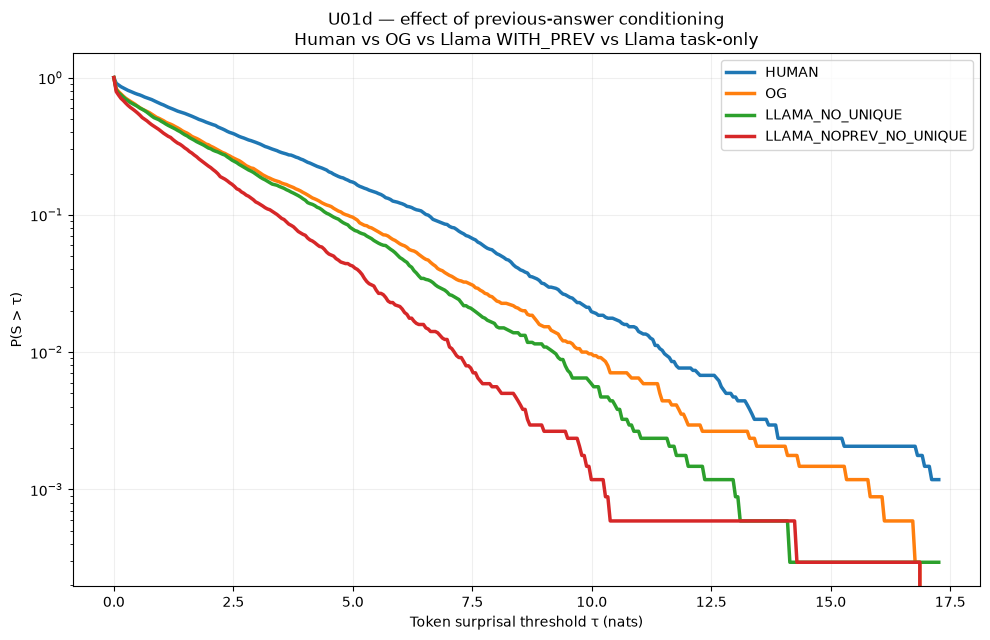

Saved: ../results/causal/U01d_unique_guard_ablation/withprev_vs_noprev_post20pct_surprisal.png


In [22]:
# ============================================================
# U01d — WITH_PREV vs NO_PREV surprisal ablation
#
# Compare:
#   HUMAN
#   OG
#   LLAMA_NO_UNIQUE          = WITH_PREV + greedy
#   LLAMA_NOPREV_NO_UNIQUE   = task-only + greedy
#
# Same protocol:
#   - Qwen/Qwen3-0.6B-Base scorer
#   - discard first 20% of OG scorer-token length
#   - common matched support across all 4 conditions
# ============================================================

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# 1. Free Llama; restore frozen Qwen scorer.
# ------------------------------------------------------------

for name in ["model", "tok"]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

SCORER_ID = "Qwen/Qwen3-0.6B-Base"

scorer_dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)

stok = AutoTokenizer.from_pretrained(
    SCORER_ID,
    use_fast=True,
)

smodel = AutoModelForCausalLM.from_pretrained(
    SCORER_ID,
    dtype=scorer_dtype,
    low_cpu_mem_usage=True,
).to(device).eval()

print("Loaded scorer:", SCORER_ID)


# ------------------------------------------------------------
# 2. Reload existing score cache.
# ------------------------------------------------------------

score_df = pd.read_parquet(SCORE_CACHE)

done = set(
    zip(
        score_df["case_id"].astype(str),
        score_df["condition"].astype(str),
    )
)


# ------------------------------------------------------------
# 3. Score ONLY NO_PREV outputs.
# ------------------------------------------------------------

for r in tqdm(
    noprev_gen.itertuples(index=False),
    total=len(noprev_gen),
    desc="Scoring NO_PREV Llama",
):

    cid = str(r.case_id)
    condition = "LLAMA_NOPREV_NO_UNIQUE"

    if (cid, condition) in done:
        continue

    text = str(r.generated_text)

    ids_all = stok(
        text,
        add_special_tokens=False,
    )["input_ids"]

    n_total = len(ids_all)

    ids = ids_all[:MAX_COMPARE_TOKENS]

    assert len(ids) >= 2, (
        cid,
        len(ids),
    )

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )

    with torch.inference_mode():

        out = smodel(
            input_ids=x,
            use_cache=False,
        )

        logits = out.logits[:, :-1, :]
        targets = x[:, 1:]

        ce = F.cross_entropy(
            logits.reshape(
                -1,
                logits.shape[-1],
            ).float(),
            targets.reshape(-1),
            reduction="none",
        )

    losses = (
        ce.detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    score_df = pd.concat(
        [
            score_df,
            pd.DataFrame([{
                "case_id": cid,
                "condition": condition,
                "n_scorer_tokens": n_total,
                "losses": losses.tolist(),
            }]),
        ],
        ignore_index=True,
    )

    score_df.to_parquet(
        SCORE_CACHE,
        index=False,
    )

    done.add((cid, condition))

    del x, out, logits, targets, ce, losses

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 4. Lookups.
# ------------------------------------------------------------

loss_lookup_prev = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    np.asarray(
        r.losses,
        dtype=float,
    )

    for r in score_df.itertuples(index=False)
}

length_lookup_prev = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    int(r.n_scorer_tokens)

    for r in score_df.itertuples(index=False)
}


CONDITIONS_PREV = [
    "HUMAN",
    "OG",
    "LLAMA_NO_UNIQUE",
    "LLAMA_NOPREV_NO_UNIQUE",
]


# ------------------------------------------------------------
# 5. Common matched post-20% support.
# ------------------------------------------------------------

suffixes_prev = {
    c: []
    for c in CONDITIONS_PREV
}

support_rows = []

for cid in og_panel["case_id"].astype(str):

    per_case = {
        c:
            loss_lookup_prev[(cid, c)]
        for c in CONDITIONS_PREV
    }

    m = min(
        len(v)
        for v in per_case.values()
    )

    og_total = (
        length_lookup_prev[
            (cid, "OG")
        ]
    )

    cut = int(
        np.ceil(
            POST_CUT_FRACTION
            * og_total
        )
    )

    if cut >= m:
        continue

    for c in CONDITIONS_PREV:
        suffixes_prev[c].append(
            per_case[c][cut:m]
        )

    support_rows.append({
        "case_id": cid,
        "cut_20pct_OG": cut,
        "matched_end": m,
        "n_post_cut": m - cut,
    })


support_prev = pd.DataFrame(
    support_rows
)

print(
    "Cases surviving 4-way support:",
    len(support_prev),
    "/ 20",
)

display(support_prev)


# ------------------------------------------------------------
# 6. Aggregate distributions.
# ------------------------------------------------------------

agg_prev = {
    c:
        np.concatenate(
            suffixes_prev[c]
        )

    for c in CONDITIONS_PREV
}


summary_rows = []

for c in CONDITIONS_PREV:

    x = agg_prev[c]

    summary_rows.append({
        "condition": c,
        "n": len(x),
        "mean": x.mean(),
        "median": np.median(x),
        "q75": np.quantile(x, .75),
        "q90": np.quantile(x, .90),
        "q95": np.quantile(x, .95),
        "q99": np.quantile(x, .99),
    })


summary_prev = (
    pd.DataFrame(summary_rows)
    .set_index("condition")
)

print(
    "\nWITH_PREV vs NO_PREV post-20% summary:"
)

display(summary_prev)


# ------------------------------------------------------------
# 7. Tail rates.
# ------------------------------------------------------------

TAILS = [4, 6, 8, 10]

tail_rows = []

for c in CONDITIONS_PREV:

    x = agg_prev[c]

    for tau in TAILS:

        mask = x > tau

        tail_rows.append({
            "condition": c,
            "tau": tau,

            "P_S_gt_tau":
                float(mask.mean()),

            "E_S_given_tail":
                float(
                    x[mask].mean()
                    if mask.any()
                    else np.nan
                ),
        })


tail_prev = pd.DataFrame(
    tail_rows
)

display(
    tail_prev.pivot(
        index="tau",
        columns="condition",
        values=[
            "P_S_gt_tau",
            "E_S_given_tail",
        ],
    )
)


# ------------------------------------------------------------
# 8. Survival curves.
# ------------------------------------------------------------

xmax = min(
    20.0,
    max(
        np.quantile(
            x,
            .999,
        )
        for x in agg_prev.values()
    ),
)

taus = np.linspace(
    0,
    xmax,
    350,
)

fig, ax = plt.subplots(
    figsize=(10, 6.5)
)

for c in CONDITIONS_PREV:

    survival = np.array([
        np.mean(
            agg_prev[c] > tau
        )
        for tau in taus
    ])

    ax.plot(
        taus,
        survival,
        linewidth=2.5,
        label=c,
    )


ax.set_yscale("log")

ax.set_xlabel(
    "Token surprisal threshold τ (nats)"
)

ax.set_ylabel(
    "P(S > τ)"
)

ax.set_title(
    "U01d — effect of previous-answer conditioning\n"
    "Human vs OG vs Llama WITH_PREV vs Llama task-only"
)

ax.grid(alpha=.2)
ax.legend()

fig.tight_layout()

PLOT_PREV = (
    OUT
    / "withprev_vs_noprev_post20pct_surprisal.png"
)

fig.savefig(
    PLOT_PREV,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", PLOT_PREV)

In [23]:
# ============================================================
# U01d — Qwen2.5 WITH_PREV / no-Unique generator baseline
#
# Direct analogue of LLAMA_NO_UNIQUE:
#
#   Qwen/Qwen2.5-1.5B-Instruct
#   + same WITH_PREV instruction/content
#   + greedy decoding
#   + FULL self-history
#   + NO Unique
#   + NO likelihood guard
#   + max_new_tokens = 640
#
# Goal:
# isolate generator-family effects on the surprisal tail.
# ============================================================

import gc
import hashlib
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# 1. Free whatever model/scorer is currently resident.
# ------------------------------------------------------------

for name in [
    "model",
    "tok",
    "smodel",
    "stok",
]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

GEN_DTYPE = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)


# ------------------------------------------------------------
# 2. Load Qwen generator.
# ------------------------------------------------------------

QWEN_ID = "Qwen/Qwen2.5-1.5B-Instruct"
MAX_NEW_TOKENS = 640

tok = AutoTokenizer.from_pretrained(
    QWEN_ID,
    use_fast=True,
)

model = AutoModelForCausalLM.from_pretrained(
    QWEN_ID,
    dtype=GEN_DTYPE,
    low_cpu_mem_usage=True,
).to(device).eval()

if tok.pad_token_id is None:
    tok.pad_token_id = tok.eos_token_id

eos = model.generation_config.eos_token_id

if eos is None:
    eos = tok.eos_token_id

EOS_IDS = (
    list(eos)
    if isinstance(eos, (list, tuple))
    else [int(eos)]
)

print("Loaded generator:", QWEN_ID)


# ------------------------------------------------------------
# 3. SAME semantic WITH_PREV prompt as the Llama baseline.
#
# We use Qwen's native chat template, but the user message itself
# is identical to the Llama WITH_PREV baseline.
# ------------------------------------------------------------

def build_messages_qwen(prompt, previous_ai):

    content = (
        f"Original task:\n{prompt}\n\n"
        f"Previous AI answer:\n{previous_ai}\n\n"
        "Generate a fresh complete answer to the original task. "
        "Preserve the substantive content of the previous AI answer."
    )

    return [{
        "role": "user",
        "content": content,
    }]


def prompt_tensor_qwen(
    prompt,
    previous_ai,
):

    rendered = tok.apply_chat_template(
        build_messages_qwen(
            prompt,
            previous_ai,
        ),
        tokenize=False,
        add_generation_prompt=True,
    )

    return tok(
        rendered,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"].to(device)


# ------------------------------------------------------------
# 4. Checkpoint.
# ------------------------------------------------------------

QWEN_PATH = (
    OUT
    / "qwen25_withprev_full_no_unique_generations.parquet"
)

if QWEN_PATH.exists():

    qwen_gen = pd.read_parquet(
        QWEN_PATH
    )

    if "status" in qwen_gen.columns:

        failed = (
            qwen_gen["status"]
            .astype(str)
            .eq("failed_exception")
        )

        if failed.any():

            print(
                "Dropping failed checkpoint rows:",
                int(failed.sum()),
            )

            qwen_gen = (
                qwen_gen.loc[~failed]
                .reset_index(drop=True)
            )

            qwen_gen.to_parquet(
                QWEN_PATH,
                index=False,
            )

else:

    qwen_gen = pd.DataFrame()


done = (
    set(
        qwen_gen["case_id"]
        .astype(str)
    )
    if len(qwen_gen)
    else set()
)


assert len(cohort) == 20
assert "prompt" in cohort.columns
assert "previous_ai" in cohort.columns


# ------------------------------------------------------------
# 5. Generate all 20.
# ------------------------------------------------------------

pbar = tqdm(
    total=len(cohort),
    initial=len(done),
    desc="Qwen2.5 WITH_PREV / no Unique",
)

for src in cohort.itertuples(index=False):

    cid = str(src.case_id)

    if cid in done:
        continue

    try:

        input_ids = prompt_tensor_qwen(
            src.prompt,
            src.previous_ai,
        )

        prompt_len = int(
            input_ids.shape[1]
        )

        with torch.inference_mode():

            generated = model.generate(
                input_ids=input_ids,

                do_sample=False,

                max_new_tokens=
                    MAX_NEW_TOKENS,

                eos_token_id=
                    EOS_IDS,

                pad_token_id=
                    tok.pad_token_id,

                use_cache=True,
            )

        new_ids = (
            generated[
                0,
                prompt_len:
            ]
            .detach()
            .cpu()
            .tolist()
        )

        text = tok.decode(
            new_ids,
            skip_special_tokens=True,
        )

        hit_eos = (
            len(new_ids) > 0
            and new_ids[-1]
            in set(EOS_IDS)
        )

        if hit_eos:

            status = "completed_eos"
            stop_reason = "eos"

        elif (
            len(new_ids)
            >= MAX_NEW_TOKENS
        ):

            status = "truncated_token_cap"
            stop_reason = "truncated"

        else:

            status = "completed_other"
            stop_reason = "other"


        row = {
            "case_id": cid,
            "source_id":
                src.source_id,

            "domain":
                src.domain,

            "condition":
                "QWEN25_NO_UNIQUE",

            "model_id":
                QWEN_ID,

            "with_prev":
                True,

            "temporal_method":
                "FULL",

            "unique_control":
                False,

            "guard_enabled":
                False,

            "do_sample":
                False,

            "generated_text":
                text,

            "generator_tokens":
                len(new_ids),

            "status":
                status,

            "stop_reason":
                stop_reason,

            "text_sha":
                hashlib.sha256(
                    text.encode()
                ).hexdigest(),
        }


    except Exception as e:

        row = {
            "case_id": cid,
            "source_id":
                src.source_id,

            "domain":
                src.domain,

            "condition":
                "QWEN25_NO_UNIQUE",

            "model_id":
                QWEN_ID,

            "with_prev":
                True,

            "temporal_method":
                "FULL",

            "unique_control":
                False,

            "guard_enabled":
                False,

            "do_sample":
                False,

            "generated_text":
                "",

            "generator_tokens":
                0,

            "status":
                "failed_exception",

            "stop_reason":
                "exception",

            "exception":
                repr(e),

            "text_sha":
                None,
        }


    qwen_gen = pd.concat(
        [
            qwen_gen,
            pd.DataFrame([row]),
        ],
        ignore_index=True,
    )

    qwen_gen.to_parquet(
        QWEN_PATH,
        index=False,
    )

    pbar.update(1)

    if row["status"] == "failed_exception":

        pbar.close()

        raise RuntimeError(
            f"{cid} failed: "
            f"{row.get('exception')}"
        )

    done.add(cid)

    del input_ids

    if "generated" in locals():
        del generated

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


pbar.close()


# ------------------------------------------------------------
# 6. Validate + summarize.
# ------------------------------------------------------------

assert len(qwen_gen) == 20
assert qwen_gen["case_id"].is_unique
assert not qwen_gen[
    "status"
].eq(
    "failed_exception"
).any()


qwen_summary = pd.DataFrame([{
    "n":
        len(qwen_gen),

    "eos":
        int(
            qwen_gen[
                "stop_reason"
            ].eq("eos").sum()
        ),

    "truncated":
        int(
            qwen_gen[
                "stop_reason"
            ].eq("truncated").sum()
        ),

    "mean_tokens":
        float(
            qwen_gen[
                "generator_tokens"
            ].mean()
        ),

    "median_tokens":
        float(
            qwen_gen[
                "generator_tokens"
            ].median()
        ),
}])

print("Saved:", QWEN_PATH)

display(qwen_summary)

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 653.13it/s]


Loaded generator: Qwen/Qwen2.5-1.5B-Instruct


Qwen2.5 WITH_PREV / no Unique: 100%|████████████████████████████████████████████████████████████████████| 20/20 [02:42<00:00,  8.11s/it]

Saved: ../results/causal/U01d_unique_guard_ablation/qwen25_withprev_full_no_unique_generations.parquet


,n,eos,truncated,mean_tokens,median_tokens
0,20,19,1,417.45,426.0


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 3246.48it/s]


Loaded scorer: Qwen/Qwen3-0.6B-Base


Scoring Qwen2.5 baseline: 100%|█████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 25.59it/s]

Cases surviving 4-way support: 20 / 20


,case_id,cut_20pct_OG,matched_end,n_post_cut
0,gate_0090,46,210,164
1,gate_0070,54,255,201
2,gate_0017,79,255,176
3,gate_0085,60,255,195
4,gate_0038,29,141,112
5,gate_0039,42,206,164
6,gate_0069,26,128,102
7,gate_0035,53,255,202
8,gate_0003,86,255,169
9,gate_0025,69,255,186



Generator-family post-20% surprisal:


,n,mean,median,q75,q90,q95,q99
condition,,,,,,,
HUMAN,3294,2.630996,1.747713,3.965485,6.596959,8.150212,11.584873
OG,3294,1.656938,0.869850,2.362531,4.537863,6.090951,9.319503
QWEN25_NO_UNIQUE,3294,1.497007,0.764741,2.252289,3.985909,5.350719,8.047208
LLAMA_NO_UNIQUE,3294,1.623444,0.837397,2.384851,4.401144,5.917176,9.217778


P_S_gt_tau                                             \
condition      HUMAN LLAMA_NO_UNIQUE        OG QWEN25_NO_UNIQUE   
tau                                                               
4           0.245902        0.121736  0.123862         0.099575   
6           0.121736        0.047055  0.051305         0.033698   
8           0.054038        0.015786  0.019429         0.010322   
10          0.021251        0.006072  0.007286         0.003036   

          E_S_given_tail                                              
condition          HUMAN LLAMA_NO_UNIQUE         OG QWEN25_NO_UNIQUE  
tau                                                                   
4               6.617889        6.030671   6.180337         5.779478  
6               8.391608        7.867176   8.042704         7.598677  
8              10.214281        9.993366  10.002402         9.685878  
10             12.350996       11.631354  11.889816        11.822375

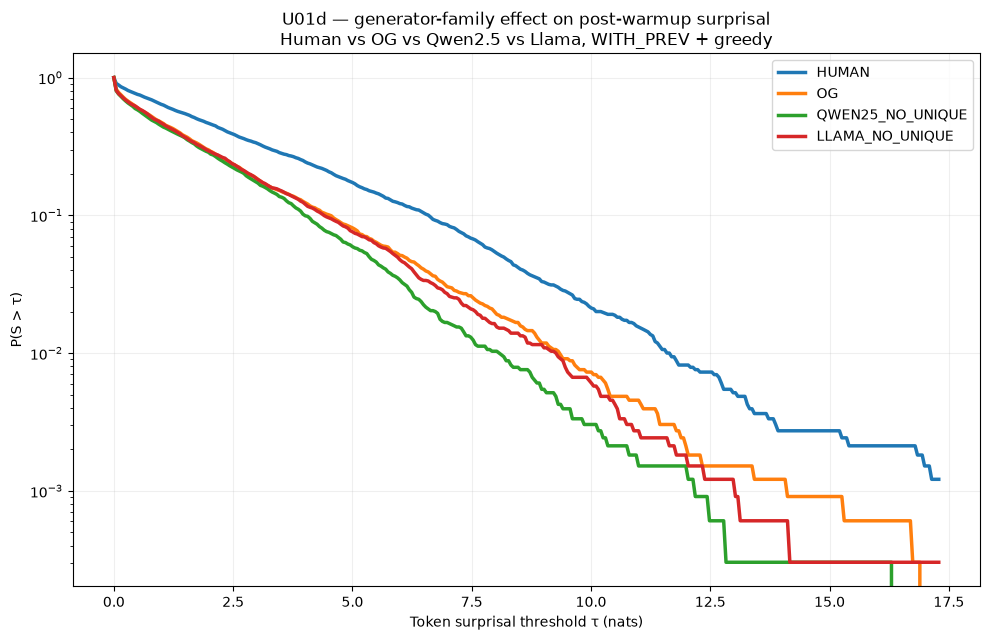

Saved: ../results/causal/U01d_unique_guard_ablation/qwen25_vs_llama_post20pct_surprisal.png


In [24]:
# ============================================================
# U01d — generator-family surprisal comparison
#
# HUMAN
# OG
# QWEN25_NO_UNIQUE
# LLAMA_NO_UNIQUE
#
# Same:
#   WITH_PREV
#   greedy
#   no Unique
#   no guard
#   post-20% OG warmup
#   common matched support
# ============================================================

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# 1. Free Qwen generator; load frozen Qwen3 scorer.
# ------------------------------------------------------------

for name in ["model", "tok"]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

SCORER_ID = "Qwen/Qwen3-0.6B-Base"

scorer_dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)

stok = AutoTokenizer.from_pretrained(
    SCORER_ID,
    use_fast=True,
)

smodel = AutoModelForCausalLM.from_pretrained(
    SCORER_ID,
    dtype=scorer_dtype,
    low_cpu_mem_usage=True,
).to(device).eval()

print("Loaded scorer:", SCORER_ID)


# ------------------------------------------------------------
# 2. Load score cache and score ONLY Qwen2.5 generations.
# ------------------------------------------------------------

score_df = pd.read_parquet(
    SCORE_CACHE
)

done = set(
    zip(
        score_df["case_id"].astype(str),
        score_df["condition"].astype(str),
    )
)

for r in tqdm(
    qwen_gen.itertuples(index=False),
    total=len(qwen_gen),
    desc="Scoring Qwen2.5 baseline",
):

    cid = str(r.case_id)
    condition = "QWEN25_NO_UNIQUE"

    if (cid, condition) in done:
        continue

    text = str(r.generated_text)

    ids_all = stok(
        text,
        add_special_tokens=False,
    )["input_ids"]

    n_total = len(ids_all)

    ids = ids_all[
        :MAX_COMPARE_TOKENS
    ]

    assert len(ids) >= 2, (
        cid,
        len(ids),
    )

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )

    with torch.inference_mode():

        out = smodel(
            input_ids=x,
            use_cache=False,
        )

        logits = out.logits[:, :-1, :]
        targets = x[:, 1:]

        ce = F.cross_entropy(
            logits.reshape(
                -1,
                logits.shape[-1],
            ).float(),
            targets.reshape(-1),
            reduction="none",
        )

    losses = (
        ce.detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    score_df = pd.concat(
        [
            score_df,
            pd.DataFrame([{
                "case_id": cid,
                "condition": condition,
                "n_scorer_tokens": n_total,
                "losses": losses.tolist(),
            }]),
        ],
        ignore_index=True,
    )

    score_df.to_parquet(
        SCORE_CACHE,
        index=False,
    )

    done.add(
        (cid, condition)
    )

    del x, out, logits, targets, ce, losses

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 3. Lookups.
# ------------------------------------------------------------

loss_lookup_family = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    np.asarray(
        r.losses,
        dtype=float,
    )

    for r in score_df.itertuples(
        index=False
    )
}

length_lookup_family = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    int(r.n_scorer_tokens)

    for r in score_df.itertuples(
        index=False
    )
}


CONDITIONS_FAMILY = [
    "HUMAN",
    "OG",
    "QWEN25_NO_UNIQUE",
    "LLAMA_NO_UNIQUE",
]


# ------------------------------------------------------------
# 4. Common matched post-20% support.
# ------------------------------------------------------------

suffixes_family = {
    c: []
    for c in CONDITIONS_FAMILY
}

support_rows = []

for cid in og_panel[
    "case_id"
].astype(str):

    per_case = {
        c:
            loss_lookup_family[
                (cid, c)
            ]

        for c in CONDITIONS_FAMILY
    }

    m = min(
        len(v)
        for v in per_case.values()
    )

    og_total = (
        length_lookup_family[
            (cid, "OG")
        ]
    )

    cut = int(
        np.ceil(
            POST_CUT_FRACTION
            * og_total
        )
    )

    if cut >= m:
        continue

    for c in CONDITIONS_FAMILY:

        suffixes_family[c].append(
            per_case[c][cut:m]
        )

    support_rows.append({
        "case_id": cid,
        "cut_20pct_OG": cut,
        "matched_end": m,
        "n_post_cut": m - cut,
    })


support_family = pd.DataFrame(
    support_rows
)

print(
    "Cases surviving 4-way support:",
    len(support_family),
    "/ 20",
)

display(support_family)


# ------------------------------------------------------------
# 5. Aggregate + summary.
# ------------------------------------------------------------

agg_family = {
    c:
        np.concatenate(
            suffixes_family[c]
        )

    for c in CONDITIONS_FAMILY
}


summary_family = pd.DataFrame([
    {
        "condition": c,

        "n":
            len(agg_family[c]),

        "mean":
            np.mean(
                agg_family[c]
            ),

        "median":
            np.median(
                agg_family[c]
            ),

        "q75":
            np.quantile(
                agg_family[c],
                .75,
            ),

        "q90":
            np.quantile(
                agg_family[c],
                .90,
            ),

        "q95":
            np.quantile(
                agg_family[c],
                .95,
            ),

        "q99":
            np.quantile(
                agg_family[c],
                .99,
            ),
    }

    for c in CONDITIONS_FAMILY
]).set_index(
    "condition"
)

print(
    "\nGenerator-family post-20% surprisal:"
)

display(summary_family)


# ------------------------------------------------------------
# 6. Tail rates.
# ------------------------------------------------------------

TAILS = [4, 6, 8, 10]

tail_rows = []

for c in CONDITIONS_FAMILY:

    x = agg_family[c]

    for tau in TAILS:

        mask = x > tau

        tail_rows.append({
            "condition": c,
            "tau": tau,

            "P_S_gt_tau":
                float(
                    mask.mean()
                ),

            "E_S_given_tail":
                float(
                    x[mask].mean()
                    if mask.any()
                    else np.nan
                ),
        })


tail_family = pd.DataFrame(
    tail_rows
)

display(
    tail_family.pivot(
        index="tau",
        columns="condition",
        values=[
            "P_S_gt_tau",
            "E_S_given_tail",
        ],
    )
)


# ------------------------------------------------------------
# 7. Survival graph.
# ------------------------------------------------------------

xmax = min(
    20.0,
    max(
        np.quantile(
            x,
            .999,
        )
        for x in agg_family.values()
    ),
)

taus = np.linspace(
    0,
    xmax,
    350,
)

fig, ax = plt.subplots(
    figsize=(10, 6.5)
)

for c in CONDITIONS_FAMILY:

    survival = np.array([
        np.mean(
            agg_family[c] > tau
        )
        for tau in taus
    ])

    ax.plot(
        taus,
        survival,
        linewidth=2.5,
        label=c,
    )


ax.set_yscale("log")

ax.set_xlabel(
    "Token surprisal threshold τ (nats)"
)

ax.set_ylabel(
    "P(S > τ)"
)

ax.set_title(
    "U01d — generator-family effect on post-warmup surprisal\n"
    "Human vs OG vs Qwen2.5 vs Llama, WITH_PREV + greedy"
)

ax.grid(alpha=.2)
ax.legend()

fig.tight_layout()

FAMILY_PLOT = (
    OUT
    / "qwen25_vs_llama_post20pct_surprisal.png"
)

fig.savefig(
    FAMILY_PLOT,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", FAMILY_PLOT)


Scorer: GPT2 | gpt2


Scoring with GPT2: 100%|███████████████████████████████████████████████████████████████████████████████| 80/80 [00:00<00:00, 102.76it/s]


Cases surviving: 20 / 20


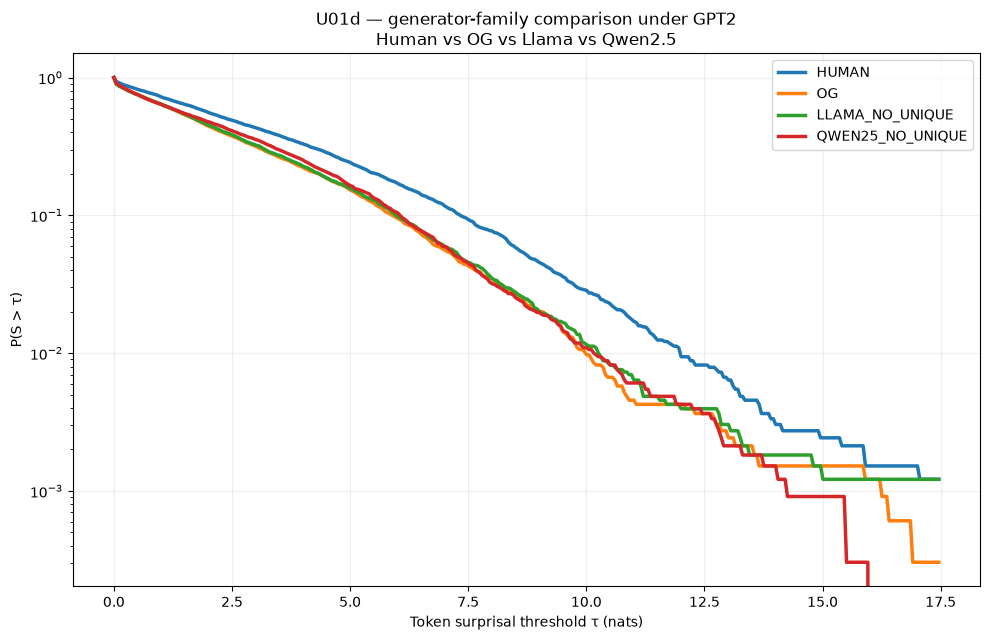


Scorer: SmolLM2 | HuggingFaceTB/SmolLM2-360M


Scoring with SmolLM2: 100%|█████████████████████████████████████████████████████████████████████████████| 80/80 [00:01<00:00, 49.21it/s]


Cases surviving: 20 / 20


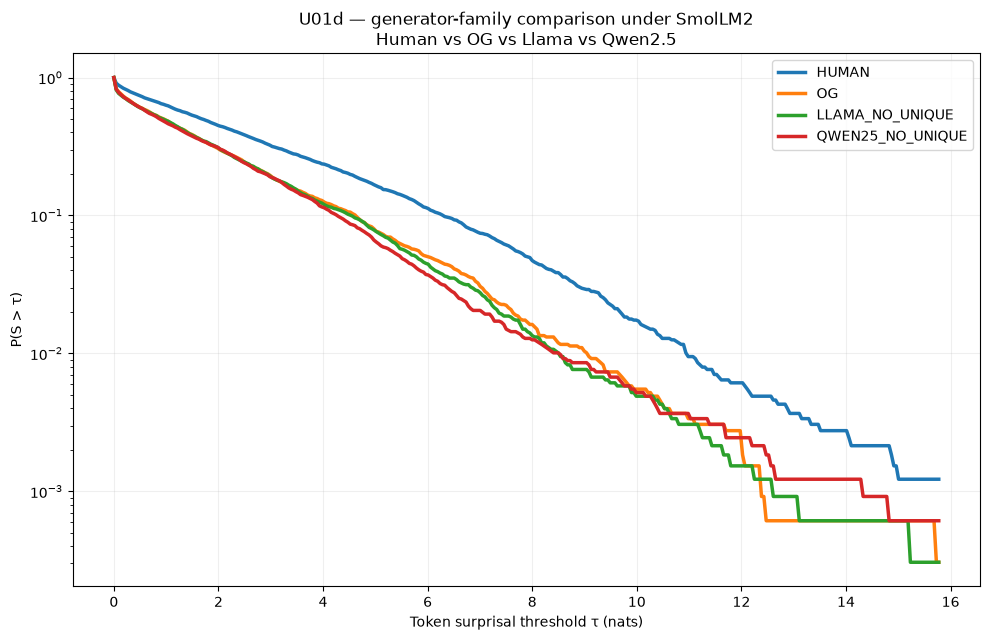


Mean surprisal by scorer:


scorer,GPT2,SmolLM2
condition,,
HUMAN,3.221955,2.535382
LLAMA_NO_UNIQUE,2.475917,1.651036
OG,2.432963,1.682182
QWEN25_NO_UNIQUE,2.555843,1.609817



Distance from OG under each independent scorer:


scorer,GPT2,SmolLM2
condition,,
HUMAN,0.788991,0.853200
LLAMA_NO_UNIQUE,0.042953,0.031146
QWEN25_NO_UNIQUE,0.122880,0.072365



Saved cross-scorer results to: ../results/causal/U01d_unique_guard_ablation/cross_scorer_generator_family


In [25]:
# ============================================================
# U01d — cross-scorer generator-family robustness
#
# Frozen texts:
#   HUMAN
#   OG
#   LLAMA_NO_UNIQUE
#   QWEN25_NO_UNIQUE
#
# Independent scorers already used elsewhere in the project:
#   GPT-2   : gpt2
#   SmolLM2 : HuggingFaceTB/SmolLM2-360M
#
# For EACH scorer independently:
#   - tokenize all four conditions with that scorer
#   - cut first 20% of that case's OG scorer-token length
#   - common matched support across all four conditions
#   - compute survival P(S > tau)
#
# This tests whether Qwen2.5 looking unusually predictable is
# specifically a Qwen3-family scorer effect.
# ============================================================

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# 1. Free current scorer/generator.
# ------------------------------------------------------------

for name in [
    "model",
    "tok",
    "smodel",
    "stok",
]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)


# ------------------------------------------------------------
# 2. Recover the four frozen texts per case.
# ------------------------------------------------------------

assert len(og_panel) == 20
assert len(plain_gen) == 20
assert len(qwen_gen) == 20
assert "human_map" in globals()
assert "human_text_lookup" in globals()

llama_lookup = (
    plain_gen
    .set_index(
        plain_gen["case_id"].astype(str)
    )["generated_text"]
    .to_dict()
)

qwen_lookup = (
    qwen_gen
    .set_index(
        qwen_gen["case_id"].astype(str)
    )["generated_text"]
    .to_dict()
)

text_panel = {}

for r in og_panel.itertuples(index=False):

    cid = str(r.case_id)

    human_sid = str(
        human_map.loc[
            cid,
            "human_source_id",
        ]
    )

    text_panel[cid] = {
        "HUMAN":
            str(
                human_text_lookup[
                    human_sid
                ]
            ),

        "OG":
            str(r.OG),

        "LLAMA_NO_UNIQUE":
            str(
                llama_lookup[cid]
            ),

        "QWEN25_NO_UNIQUE":
            str(
                qwen_lookup[cid]
            ),
    }


CONDITIONS = [
    "HUMAN",
    "OG",
    "LLAMA_NO_UNIQUE",
    "QWEN25_NO_UNIQUE",
]

assert len(text_panel) == 20


# ------------------------------------------------------------
# 3. Independent scorer definitions.
# ------------------------------------------------------------

SCORERS = {
    "GPT2":
        "gpt2",

    "SmolLM2":
        "HuggingFaceTB/SmolLM2-360M",
}

MAX_COMPARE_TOKENS = 256
POST_CUT_FRACTION = 0.20

CROSS_OUT = (
    OUT
    / "cross_scorer_generator_family"
)

CROSS_OUT.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 4. Score one text.
# ------------------------------------------------------------

def score_text(
    text,
    tokenizer,
    scorer,
):

    ids_all = tokenizer(
        text,
        add_special_tokens=False,
    )["input_ids"]

    n_total = len(ids_all)

    ids = ids_all[
        :MAX_COMPARE_TOKENS
    ]

    if len(ids) < 2:
        return n_total, np.array(
            [],
            dtype=np.float32,
        )

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )

    with torch.inference_mode():

        out = scorer(
            input_ids=x,
            use_cache=False,
        )

        logits = (
            out.logits[
                :, :-1, :
            ]
            .float()
        )

        targets = x[:, 1:]

        loss = F.cross_entropy(
            logits.reshape(
                -1,
                logits.shape[-1],
            ),
            targets.reshape(-1),
            reduction="none",
        )

    arr = (
        loss
        .detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    del x, out, logits, targets, loss

    return n_total, arr


# ------------------------------------------------------------
# 5. Run scorers sequentially.
# ------------------------------------------------------------

all_summaries = []
all_tail_rows = []
all_support = []
all_survival = {}

for scorer_name, scorer_id in SCORERS.items():

    print(
        "\n========================================"
    )
    print(
        "Scorer:",
        scorer_name,
        "|",
        scorer_id,
    )
    print(
        "========================================"
    )

    cache_path = (
        CROSS_OUT
        / f"{scorer_name}_token_losses.parquet"
    )

    if cache_path.exists():

        scored = pd.read_parquet(
            cache_path
        )

    else:

        scored = pd.DataFrame()


    done = (
        set(
            zip(
                scored["case_id"].astype(str),
                scored["condition"].astype(str),
            )
        )
        if len(scored)
        else set()
    )


    # --------------------------------------------------------
    # Load this scorer.
    # --------------------------------------------------------

    tokenizer = (
        AutoTokenizer
        .from_pretrained(
            scorer_id,
            use_fast=True,
        )
    )

    scorer = (
        AutoModelForCausalLM
        .from_pretrained(
            scorer_id,
            dtype=dtype,
            low_cpu_mem_usage=True,
        )
        .to(device)
        .eval()
    )


    # --------------------------------------------------------
    # Score 20 × 4 frozen texts.
    # --------------------------------------------------------

    jobs = [
        (
            cid,
            condition,
            text_panel[cid][condition],
        )

        for cid in text_panel
        for condition in CONDITIONS
    ]

    for cid, condition, text in tqdm(
        jobs,
        desc=f"Scoring with {scorer_name}",
    ):

        if (
            cid,
            condition,
        ) in done:
            continue

        n_total, losses = score_text(
            text,
            tokenizer,
            scorer,
        )

        row = pd.DataFrame([{
            "scorer":
                scorer_name,

            "scorer_id":
                scorer_id,

            "case_id":
                cid,

            "condition":
                condition,

            "n_scorer_tokens":
                n_total,

            "losses":
                losses.tolist(),
        }])

        scored = pd.concat(
            [
                scored,
                row,
            ],
            ignore_index=True,
        )

        scored.to_parquet(
            cache_path,
            index=False,
        )

        done.add(
            (
                cid,
                condition,
            )
        )


    # --------------------------------------------------------
    # Lookups.
    # --------------------------------------------------------

    loss_lookup = {
        (
            str(r.case_id),
            str(r.condition),
        ):
        np.asarray(
            r.losses,
            dtype=float,
        )

        for r in scored.itertuples(
            index=False
        )
    }

    length_lookup = {
        (
            str(r.case_id),
            str(r.condition),
        ):
        int(
            r.n_scorer_tokens
        )

        for r in scored.itertuples(
            index=False
        )
    }


    # --------------------------------------------------------
    # Common matched support.
    # --------------------------------------------------------

    suffixes = {
        c: []
        for c in CONDITIONS
    }

    support_rows = []

    for cid in text_panel:

        per_case = {
            c:
                loss_lookup[
                    (cid, c)
                ]

            for c in CONDITIONS
        }

        m = min(
            len(x)
            for x in per_case.values()
        )

        og_total = (
            length_lookup[
                (cid, "OG")
            ]
        )

        cut = int(
            np.ceil(
                POST_CUT_FRACTION
                * og_total
            )
        )

        if cut >= m:
            continue

        for c in CONDITIONS:

            suffixes[c].append(
                per_case[c][cut:m]
            )

        support_rows.append({
            "scorer":
                scorer_name,

            "case_id":
                cid,

            "cut_20pct_OG":
                cut,

            "matched_end":
                m,

            "n_post_cut":
                m - cut,
        })


    support_df = pd.DataFrame(
        support_rows
    )

    all_support.append(
        support_df
    )

    print(
        "Cases surviving:",
        len(support_df),
        "/ 20",
    )


    # --------------------------------------------------------
    # Aggregate.
    # --------------------------------------------------------

    agg = {
        c:
            np.concatenate(
                suffixes[c]
            )

        for c in CONDITIONS
    }


    # --------------------------------------------------------
    # Summary.
    # --------------------------------------------------------

    for c in CONDITIONS:

        x = agg[c]

        all_summaries.append({
            "scorer":
                scorer_name,

            "condition":
                c,

            "n":
                len(x),

            "mean":
                x.mean(),

            "median":
                np.median(x),

            "q75":
                np.quantile(
                    x,
                    .75,
                ),

            "q90":
                np.quantile(
                    x,
                    .90,
                ),

            "q95":
                np.quantile(
                    x,
                    .95,
                ),

            "q99":
                np.quantile(
                    x,
                    .99,
                ),
        })


    # --------------------------------------------------------
    # Tail frequencies.
    # --------------------------------------------------------

    # Absolute thresholds have different meaning across scorers,
    # but are still useful within each scorer.
    TAILS = [
        4,
        6,
        8,
        10,
    ]

    for c in CONDITIONS:

        x = agg[c]

        for tau in TAILS:

            mask = x > tau

            all_tail_rows.append({
                "scorer":
                    scorer_name,

                "condition":
                    c,

                "tau":
                    tau,

                "P_S_gt_tau":
                    float(
                        mask.mean()
                    ),

                "E_S_given_tail":
                    float(
                        x[mask].mean()
                        if mask.any()
                        else np.nan
                    ),
            })


    # --------------------------------------------------------
    # Survival curve.
    # --------------------------------------------------------

    xmax = min(
        20.0,
        max(
            np.quantile(
                x,
                .999,
            )
            for x in agg.values()
        ),
    )

    taus = np.linspace(
        0,
        xmax,
        350,
    )

    survival = {}

    for c in CONDITIONS:

        survival[c] = np.array([
            np.mean(
                agg[c] > tau
            )

            for tau in taus
        ])

    all_survival[
        scorer_name
    ] = {
        "taus":
            taus,

        "survival":
            survival,
    }


    fig, ax = plt.subplots(
        figsize=(
            10,
            6.5,
        )
    )

    for c in CONDITIONS:

        ax.plot(
            taus,
            survival[c],
            linewidth=2.5,
            label=c,
        )

    ax.set_yscale(
        "log"
    )

    ax.set_xlabel(
        "Token surprisal threshold τ (nats)"
    )

    ax.set_ylabel(
        "P(S > τ)"
    )

    ax.set_title(
        f"U01d — generator-family comparison under {scorer_name}\n"
        "Human vs OG vs Llama vs Qwen2.5"
    )

    ax.grid(
        alpha=.2
    )

    ax.legend()

    fig.tight_layout()

    fig.savefig(
        CROSS_OUT
        / f"{scorer_name}_generator_family_survival.png",

        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


    # --------------------------------------------------------
    # Free this scorer before loading the next.
    # --------------------------------------------------------

    del scorer
    del tokenizer

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


# ------------------------------------------------------------
# 6. Combined summary.
# ------------------------------------------------------------

cross_summary = pd.DataFrame(
    all_summaries
)

cross_tail = pd.DataFrame(
    all_tail_rows
)

cross_support = pd.concat(
    all_support,
    ignore_index=True,
)

cross_summary.to_csv(
    CROSS_OUT
    / "cross_scorer_summary.csv",
    index=False,
)

cross_tail.to_csv(
    CROSS_OUT
    / "cross_scorer_tail_rates.csv",
    index=False,
)

cross_support.to_csv(
    CROSS_OUT
    / "cross_scorer_support.csv",
    index=False,
)


print(
    "\nMean surprisal by scorer:"
)

display(
    cross_summary.pivot(
        index="condition",
        columns="scorer",
        values="mean",
    )
)


# ------------------------------------------------------------
# 7. Most useful invariant comparison:
#    distance from OG within each scorer.
# ------------------------------------------------------------

mean_table = (
    cross_summary
    .pivot(
        index="condition",
        columns="scorer",
        values="mean",
    )
)

distance_rows = []

for scorer_name in SCORERS:

    og_mean = float(
        mean_table.loc[
            "OG",
            scorer_name,
        ]
    )

    for c in [
        "HUMAN",
        "LLAMA_NO_UNIQUE",
        "QWEN25_NO_UNIQUE",
    ]:

        value = float(
            mean_table.loc[
                c,
                scorer_name,
            ]
        )

        distance_rows.append({
            "scorer":
                scorer_name,

            "condition":
                c,

            "mean":
                value,

            "OG_mean":
                og_mean,

            "delta_vs_OG":
                value - og_mean,

            "abs_delta_vs_OG":
                abs(
                    value - og_mean
                ),
        })


distance_df = pd.DataFrame(
    distance_rows
)

print(
    "\nDistance from OG under each independent scorer:"
)

display(
    distance_df.pivot(
        index="condition",
        columns="scorer",
        values="abs_delta_vs_OG",
    )
)

print(
    "\nSaved cross-scorer results to:",
    CROSS_OUT,
)


Scorer: Qwen3 | Qwen/Qwen3-0.6B-Base


Scoring Qwen3: 100%|██████████████████████████████████████████████████████████████████████████████████| 120/120 [00:03<00:00, 30.35it/s]


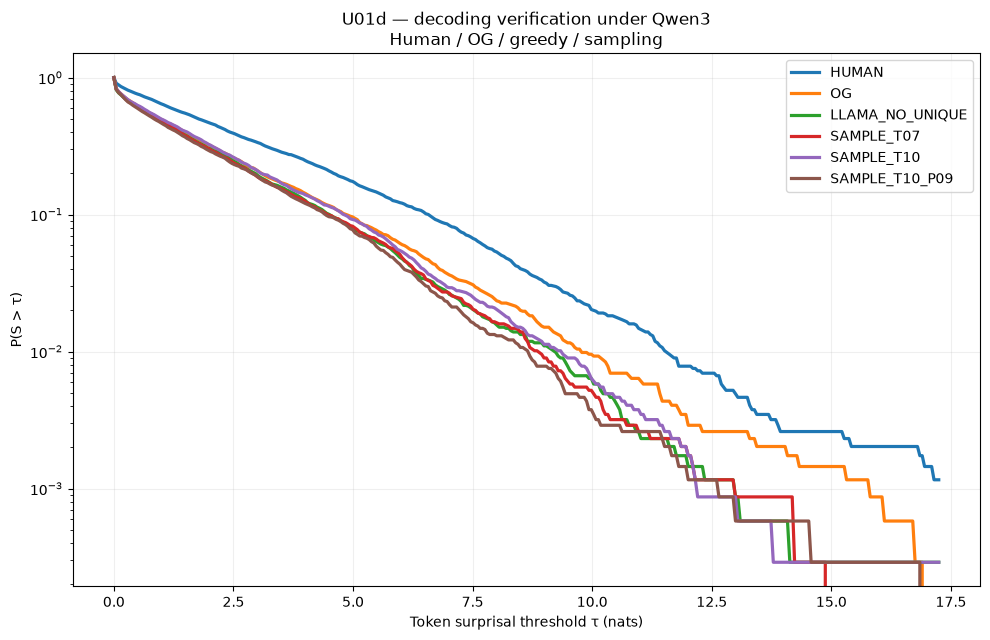


Scorer: GPT2 | gpt2


Scoring GPT2: 100%|███████████████████████████████████████████████████████████████████████████████████| 120/120 [00:01<00:00, 91.44it/s]


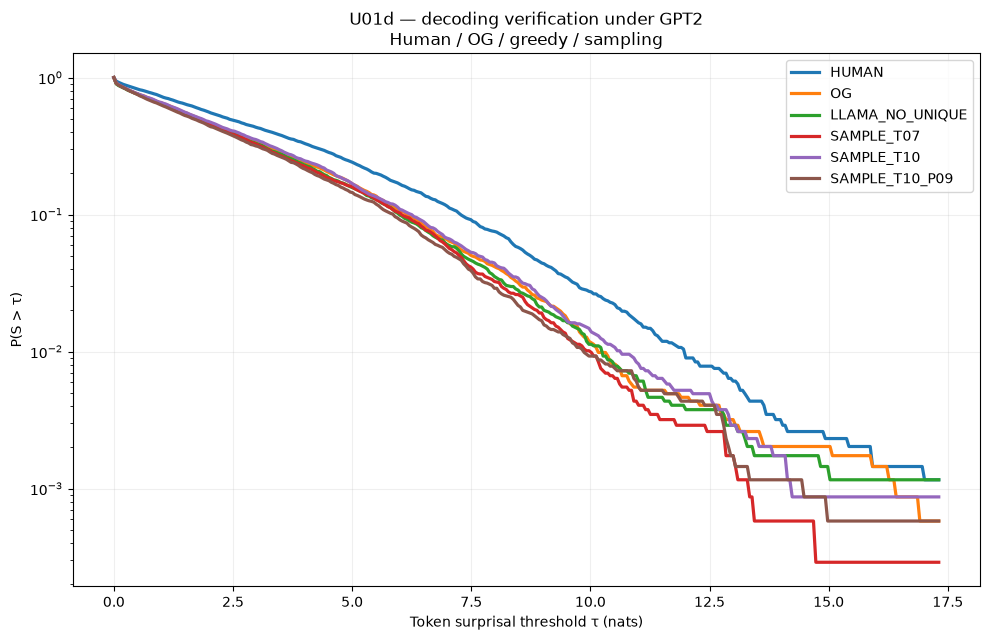


Scorer: SmolLM2 | HuggingFaceTB/SmolLM2-360M


Scoring SmolLM2: 100%|████████████████████████████████████████████████████████████████████████████████| 120/120 [00:02<00:00, 42.86it/s]


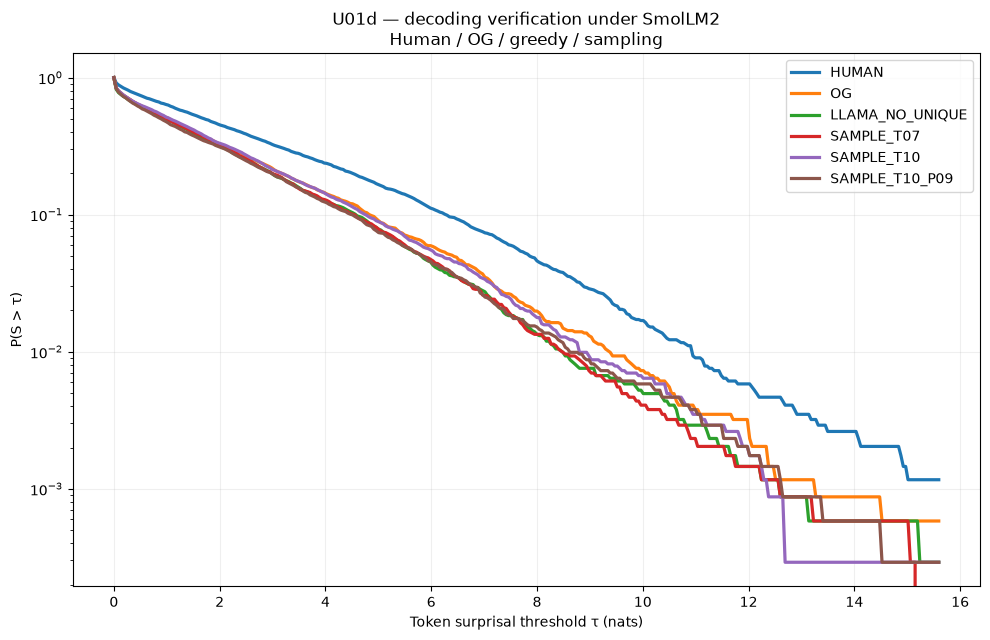


Mean surprisal:


scorer,GPT2,Qwen3,SmolLM2
condition,,,
HUMAN,3.210556,2.637328,2.542102
LLAMA_NO_UNIQUE,2.497175,1.667899,1.685992
OG,2.560477,1.797093,1.804633
SAMPLE_T07,2.466505,1.654616,1.702801
SAMPLE_T10,2.608147,1.769826,1.801693
SAMPLE_T10_P09,2.393915,1.602619,1.654433



PRIMARY RESULT — paired Sample minus Greedy:


,scorer,sampling_arm,mean_delta_S,ci_low,ci_high,positive_case_fraction,median_delta_S,mean_abs_delta
3,GPT2,SAMPLE_T07,-0.030614,-0.127538,0.060773,0.40,-0.028027,0.147525
0,Qwen3,SAMPLE_T07,-0.013552,-0.097772,0.068253,0.50,0.003480,0.123294
6,SmolLM2,SAMPLE_T07,0.010856,-0.065588,0.086052,0.55,0.010611,0.117695
4,GPT2,SAMPLE_T10,0.118573,-0.044457,0.286359,0.70,0.081112,0.274975
1,Qwen3,SAMPLE_T10,0.109324,-0.086427,0.302581,0.65,0.064285,0.287881
7,SmolLM2,SAMPLE_T10,0.118004,-0.068885,0.292836,0.75,0.111543,0.290050
5,GPT2,SAMPLE_T10_P09,-0.096995,-0.201810,0.004673,0.20,-0.046772,0.172388
2,Qwen3,SAMPLE_T10_P09,-0.059008,-0.151555,0.019693,0.50,0.007675,0.128599
8,SmolLM2,SAMPLE_T10_P09,-0.031331,-0.119596,0.053842,0.35,-0.015189,0.144983



Tail rates at τ=6:


scorer,GPT2,Qwen3,SmolLM2
condition,,,
HUMAN,0.166570,0.121309,0.111532
LLAMA_NO_UNIQUE,0.099363,0.047771,0.044554
OG,0.107474,0.061089,0.059115
SAMPLE_T07,0.102549,0.049797,0.047175
SAMPLE_T10,0.109502,0.054430,0.055329
SAMPLE_T10_P09,0.091541,0.041980,0.045719



Cross-scorer decoding verdict:


,scorer,sampling_arm,mean_delta_S,ci_low,ci_high,positive_case_fraction,direction_supported
0,Qwen3,SAMPLE_T07,-0.013552,-0.097772,0.068253,0.50,False
1,Qwen3,SAMPLE_T10,0.109324,-0.086427,0.302581,0.65,False
2,Qwen3,SAMPLE_T10_P09,-0.059008,-0.151555,0.019693,0.50,False
3,GPT2,SAMPLE_T07,-0.030614,-0.127538,0.060773,0.40,False
4,GPT2,SAMPLE_T10,0.118573,-0.044457,0.286359,0.70,False
5,GPT2,SAMPLE_T10_P09,-0.096995,-0.201810,0.004673,0.20,False
6,SmolLM2,SAMPLE_T07,0.010856,-0.065588,0.086052,0.55,False
7,SmolLM2,SAMPLE_T10,0.118004,-0.068885,0.292836,0.75,False
8,SmolLM2,SAMPLE_T10_P09,-0.031331,-0.119596,0.053842,0.35,False



Saved verification outputs to: ../results/causal/U01d_unique_guard_ablation/decoding_cross_scorer_verification


In [26]:
# ============================================================
# U01d — immediate decoding verification across 3 scorers
#
# Question:
#   Does stochastic decoding reliably increase post-warmup
#   surprisal relative to greedy Llama decoding?
#
# Frozen text conditions:
#   HUMAN                 reference only
#   OG                    reference only
#   LLAMA_NO_UNIQUE       greedy
#   SAMPLE_T07            T=.7,  p=1
#   SAMPLE_T10            T=1.0, p=1
#   SAMPLE_T10_P09        T=1.0, p=.9
#
# Scorers:
#   Qwen3-0.6B
#   GPT-2
#   SmolLM2-360M
#
# Protocol:
#   - scorer-specific tokenization
#   - first 20% of that case's OG scorer-token length removed
#   - common matched support across all 6 conditions
#   - paired per-case Sample - Greedy deltas
#   - bootstrap 95% CI across the 20 cases
#
# Positive delta = sampling raises surprisal vs greedy.
# ============================================================

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from pathlib import Path
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# 0. Preconditions
# ------------------------------------------------------------

assert len(og_panel) == 20
assert len(plain_gen) == 20
assert len(sample_gen) == 60

assert "human_map" in globals()
assert "human_text_lookup" in globals()

SAMPLE_ARMS = [
    "SAMPLE_T07",
    "SAMPLE_T10",
    "SAMPLE_T10_P09",
]

CONDITIONS = [
    "HUMAN",
    "OG",
    "LLAMA_NO_UNIQUE",
    *SAMPLE_ARMS,
]

SCORERS = {
    "Qwen3":
        "Qwen/Qwen3-0.6B-Base",

    "GPT2":
        "gpt2",

    "SmolLM2":
        "HuggingFaceTB/SmolLM2-360M",
}

MAX_COMPARE_TOKENS = 256
POST_CUT_FRACTION = 0.20

VERIFY_OUT = (
    OUT
    / "decoding_cross_scorer_verification"
)

VERIFY_OUT.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 1. Freeze exact texts.
# ------------------------------------------------------------

greedy_lookup = (
    plain_gen
    .assign(
        case_id=
            plain_gen["case_id"].astype(str)
    )
    .set_index("case_id")[
        "generated_text"
    ]
    .to_dict()
)

sample_lookup = {
    (
        str(r.case_id),
        str(r.decoding_arm),
    ):
    str(r.generated_text)

    for r in sample_gen.itertuples(
        index=False
    )
}

text_panel = {}

for r in og_panel.itertuples(index=False):

    cid = str(r.case_id)

    human_sid = str(
        human_map.loc[
            cid,
            "human_source_id",
        ]
    )

    text_panel[cid] = {
        "HUMAN":
            str(
                human_text_lookup[
                    human_sid
                ]
            ),

        "OG":
            str(r.OG),

        "LLAMA_NO_UNIQUE":
            str(
                greedy_lookup[cid]
            ),

        "SAMPLE_T07":
            sample_lookup[
                (cid, "SAMPLE_T07")
            ],

        "SAMPLE_T10":
            sample_lookup[
                (cid, "SAMPLE_T10")
            ],

        "SAMPLE_T10_P09":
            sample_lookup[
                (cid, "SAMPLE_T10_P09")
            ],
    }

assert len(text_panel) == 20


# ------------------------------------------------------------
# 2. Free resident models.
# ------------------------------------------------------------

for name in [
    "model",
    "tok",
    "smodel",
    "stok",
]:

    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

dtype = (
    torch.float16
    if device.type == "cuda"
    else torch.float32
)


# ------------------------------------------------------------
# 3. Helpers.
# ------------------------------------------------------------

def score_text(
    text,
    tokenizer,
    scorer,
):

    ids_all = tokenizer(
        text,
        add_special_tokens=False,
    )["input_ids"]

    n_total = len(ids_all)

    ids = ids_all[
        :MAX_COMPARE_TOKENS
    ]

    assert len(ids) >= 2

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )

    with torch.inference_mode():

        out = scorer(
            input_ids=x,
            use_cache=False,
        )

        logits = (
            out.logits[
                :, :-1, :
            ]
            .float()
        )

        targets = x[:, 1:]

        losses = F.cross_entropy(
            logits.reshape(
                -1,
                logits.shape[-1],
            ),
            targets.reshape(-1),
            reduction="none",
        )

    arr = (
        losses
        .detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    del (
        x,
        out,
        logits,
        targets,
        losses,
    )

    return n_total, arr


def bootstrap_mean_ci(
    values,
    n_boot=10000,
    seed=20260917,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    rng = np.random.default_rng(
        seed
    )

    boots = np.empty(
        n_boot,
        dtype=float,
    )

    n = len(values)

    for i in range(n_boot):

        sample = rng.choice(
            values,
            size=n,
            replace=True,
        )

        boots[i] = sample.mean()

    return (
        float(values.mean()),
        float(
            np.quantile(
                boots,
                .025,
            )
        ),
        float(
            np.quantile(
                boots,
                .975,
            )
        ),
    )


# ------------------------------------------------------------
# 4. Score all conditions under all scorers.
# ------------------------------------------------------------

summary_rows = []
paired_rows = []
tail_rows = []
survival_store = {}

for scorer_name, scorer_id in SCORERS.items():

    print(
        "\n=============================="
    )
    print(
        "Scorer:",
        scorer_name,
        "|",
        scorer_id,
    )
    print(
        "=============================="
    )

    cache_path = (
        VERIFY_OUT
        / f"{scorer_name}_losses.parquet"
    )

    if cache_path.exists():

        scored = pd.read_parquet(
            cache_path
        )

    else:

        scored = pd.DataFrame()


    done = (
        set(
            zip(
                scored[
                    "case_id"
                ].astype(str),

                scored[
                    "condition"
                ].astype(str),
            )
        )
        if len(scored)
        else set()
    )


    tokenizer = (
        AutoTokenizer
        .from_pretrained(
            scorer_id,
            use_fast=True,
        )
    )

    scorer = (
        AutoModelForCausalLM
        .from_pretrained(
            scorer_id,
            dtype=dtype,
            low_cpu_mem_usage=True,
        )
        .to(device)
        .eval()
    )


    jobs = [
        (
            cid,
            condition,
            text_panel[
                cid
            ][
                condition
            ],
        )

        for cid in text_panel
        for condition in CONDITIONS
    ]


    for cid, condition, text in tqdm(
        jobs,
        desc=f"Scoring {scorer_name}",
    ):

        if (
            cid,
            condition,
        ) in done:

            continue

        n_total, losses = score_text(
            text,
            tokenizer,
            scorer,
        )

        scored = pd.concat(
            [
                scored,

                pd.DataFrame([{
                    "case_id":
                        cid,

                    "condition":
                        condition,

                    "n_scorer_tokens":
                        n_total,

                    "losses":
                        losses.tolist(),
                }]),
            ],
            ignore_index=True,
        )

        scored.to_parquet(
            cache_path,
            index=False,
        )

        done.add(
            (
                cid,
                condition,
            )
        )


    # --------------------------------------------------------
    # 5. Matched post-20% support.
    # --------------------------------------------------------

    loss_lookup = {
        (
            str(r.case_id),
            str(r.condition),
        ):
        np.asarray(
            r.losses,
            dtype=float,
        )

        for r in scored.itertuples(
            index=False
        )
    }

    length_lookup = {
        (
            str(r.case_id),
            str(r.condition),
        ):
        int(
            r.n_scorer_tokens
        )

        for r in scored.itertuples(
            index=False
        )
    }


    suffixes = {
        c: []
        for c in CONDITIONS
    }

    case_means = []

    for cid in text_panel:

        per_case = {
            c:
                loss_lookup[
                    (cid, c)
                ]

            for c in CONDITIONS
        }

        m = min(
            len(v)
            for v in per_case.values()
        )

        og_total = (
            length_lookup[
                (cid, "OG")
            ]
        )

        cut = int(
            np.ceil(
                POST_CUT_FRACTION
                * og_total
            )
        )

        if cut >= m:
            continue

        row = {
            "scorer":
                scorer_name,

            "case_id":
                cid,
        }

        for c in CONDITIONS:

            suffix = (
                per_case[c][
                    cut:m
                ]
            )

            suffixes[c].append(
                suffix
            )

            row[c] = float(
                suffix.mean()
            )

        case_means.append(
            row
        )


    case_means = pd.DataFrame(
        case_means
    )

    assert len(case_means) == 20


    # --------------------------------------------------------
    # 6. Aggregate condition summaries.
    # --------------------------------------------------------

    agg = {
        c:
            np.concatenate(
                suffixes[c]
            )

        for c in CONDITIONS
    }

    for c in CONDITIONS:

        x = agg[c]

        summary_rows.append({
            "scorer":
                scorer_name,

            "condition":
                c,

            "n_tokens":
                len(x),

            "mean":
                x.mean(),

            "median":
                np.median(x),

            "q90":
                np.quantile(
                    x,
                    .90,
                ),

            "q95":
                np.quantile(
                    x,
                    .95,
                ),

            "q99":
                np.quantile(
                    x,
                    .99,
                ),
        })


    # --------------------------------------------------------
    # 7. PRIMARY verification:
    #    paired Sample - Greedy effects by case.
    # --------------------------------------------------------

    greedy = (
        case_means[
            "LLAMA_NO_UNIQUE"
        ]
        .to_numpy()
    )

    for arm in SAMPLE_ARMS:

        sampled = (
            case_means[
                arm
            ]
            .to_numpy()
        )

        delta = (
            sampled
            - greedy
        )

        mean_delta, ci_low, ci_high = (
            bootstrap_mean_ci(
                delta
            )
        )

        paired_rows.append({
            "scorer":
                scorer_name,

            "sampling_arm":
                arm,

            "mean_delta_S":
                mean_delta,

            "ci_low":
                ci_low,

            "ci_high":
                ci_high,

            "positive_case_fraction":
                float(
                    np.mean(
                        delta > 0
                    )
                ),

            "median_delta_S":
                float(
                    np.median(
                        delta
                    )
                ),

            "mean_abs_delta":
                float(
                    np.mean(
                        np.abs(
                            delta
                        )
                    )
                ),
        })


    # --------------------------------------------------------
    # 8. Tail comparison.
    # --------------------------------------------------------

    for tau in [
        4,
        6,
        8,
        10,
    ]:

        for c in CONDITIONS:

            x = agg[c]

            tail_rows.append({
                "scorer":
                    scorer_name,

                "condition":
                    c,

                "tau":
                    tau,

                "P_S_gt_tau":
                    float(
                        np.mean(
                            x > tau
                        )
                    ),
            })


    # --------------------------------------------------------
    # 9. Survival graph for this scorer.
    # --------------------------------------------------------

    xmax = min(
        20.0,

        max(
            np.quantile(
                x,
                .999,
            )

            for x in agg.values()
        ),
    )

    taus = np.linspace(
        0,
        xmax,
        350,
    )

    survival_store[
        scorer_name
    ] = {}

    fig, ax = plt.subplots(
        figsize=(10, 6.5)
    )

    for c in CONDITIONS:

        survival = np.array([
            np.mean(
                agg[c] > tau
            )

            for tau in taus
        ])

        survival_store[
            scorer_name
        ][c] = survival

        ax.plot(
            taus,
            survival,
            linewidth=2.3,
            label=c,
        )

    ax.set_yscale(
        "log"
    )

    ax.set_xlabel(
        "Token surprisal threshold τ (nats)"
    )

    ax.set_ylabel(
        "P(S > τ)"
    )

    ax.set_title(
        f"U01d — decoding verification under {scorer_name}\n"
        "Human / OG / greedy / sampling"
    )

    ax.grid(
        alpha=.2
    )

    ax.legend()

    fig.tight_layout()

    fig.savefig(
        VERIFY_OUT
        / f"{scorer_name}_decoding_survival.png",

        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


    # --------------------------------------------------------
    # Free scorer before next one.
    # --------------------------------------------------------

    del scorer
    del tokenizer

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


# ------------------------------------------------------------
# 10. Final verification tables.
# ------------------------------------------------------------

summary_decoding_xs = pd.DataFrame(
    summary_rows
)

paired_decoding_xs = pd.DataFrame(
    paired_rows
)

tail_decoding_xs = pd.DataFrame(
    tail_rows
)


print(
    "\nMean surprisal:"
)

display(
    summary_decoding_xs.pivot(
        index="condition",
        columns="scorer",
        values="mean",
    )
)


print(
    "\nPRIMARY RESULT — paired Sample minus Greedy:"
)

display(
    paired_decoding_xs.sort_values(
        [
            "sampling_arm",
            "scorer",
        ]
    )
)


print(
    "\nTail rates at τ=6:"
)

display(
    tail_decoding_xs[
        tail_decoding_xs[
            "tau"
        ].eq(6)
    ]
    .pivot(
        index="condition",
        columns="scorer",
        values="P_S_gt_tau",
    )
)


# ------------------------------------------------------------
# 11. Compact robustness verdict table.
#
# "direction_supported":
#     bootstrap CI entirely above zero
#
# This is only a convenient diagnostic; inspect magnitudes too.
# ------------------------------------------------------------

verdict = (
    paired_decoding_xs
    .assign(
        direction_supported=
            paired_decoding_xs[
                "ci_low"
            ] > 0
    )
)

print(
    "\nCross-scorer decoding verdict:"
)

display(
    verdict[
        [
            "scorer",
            "sampling_arm",
            "mean_delta_S",
            "ci_low",
            "ci_high",
            "positive_case_fraction",
            "direction_supported",
        ]
    ]
)


summary_decoding_xs.to_csv(
    VERIFY_OUT
    / "decoding_summary.csv",
    index=False,
)

paired_decoding_xs.to_csv(
    VERIFY_OUT
    / "paired_sample_minus_greedy.csv",
    index=False,
)

tail_decoding_xs.to_csv(
    VERIFY_OUT
    / "tail_rates.csv",
    index=False,
)

print(
    "\nSaved verification outputs to:",
    VERIFY_OUT,
)